<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** uRNA source score (lambda = 0.5), target score, uRNA-mediated cell-cell contacts and OPC contact analysis in the mouse brain.
> - **Manuscript panels:** Fig. 5B-E, 5G; ED Fig. 7B, 7D-F
> - **Inputs:** `data_annotated_lambda0.5.zarr` from `recompute_source_score_final_lambda05.py`
> - **Outputs:** Source-score violins, spatial maps, contact heatmaps, OPC contact plots
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
from pathlib import Path
import pandas as pd

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
from troutpy import pl
from troutpy import tl
from troutpy import pp

# read dataset

In [3]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k")


Path(saving_path).mkdir(parents=True, exist_ok=True)

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_annotated_lambda0.5.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


# Source_score

We compute the contribution score

In [4]:
sdata['table'].obs

,cell_id,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,...,area,perimeter,solidity,major_axis_length,equivalent_diameter,circularity,protrusion_length,morphological_complexity,urna_source_score,cell_type
126,aaiekoom-1,876,0,0,0,0,0,876,52.155471,32.060939,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.257846,Oligodendrocytes
170,aalcbbkg-1,1825,0,0,0,4,0,1829,90.493128,63.354221,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.425582,Microglia
171,aalcdlim-1,1323,0,0,0,1,0,1324,64.392815,33.505939,...,2004.0,178.752309,0.956563,64.221004,50.513088,0.788142,6.853958,0.043437,12.975060,Ependymal cells
172,aalcdofj-1,978,0,0,0,0,1,979,47.910783,30.796564,...,1426.0,143.639610,0.960269,49.514309,42.610323,0.868522,3.451993,0.039731,46.796027,Ependymal cells
173,aalcogij-1,722,1,0,0,0,0,723,31.202970,NaN,...,1061.0,125.195959,0.963669,38.486226,36.754689,0.850638,0.865769,0.036331,15.044899,Ependymal cells
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63152,oikgbcfe-1,750,0,0,0,0,0,750,62.135002,35.583126,...,480.0,81.840620,0.963855,28.762827,24.721549,0.900561,2.020639,0.036145,186.088033,Astrocytes Thal.
63153,oikgokio-1,846,0,0,0,0,0,846,72.069378,40.189064,...,1376.0,141.296465,0.971751,49.555237,41.856632,0.866095,3.849303,0.028249,86.689809,Microglia
63154,oikhllhm-1,1332,0,0,0,0,0,1332,157.459849,43.214533,...,1596.0,168.267027,0.880309,60.257888,45.078712,0.708345,7.589588,0.119691,212.776968,Astrocytes Thal.
63155,oikjgbch-1,476,0,0,0,0,0,476,47.820470,47.820470,...,3487.0,232.793939,0.954558,74.784464,66.631721,0.808572,4.076371,0.045442,138.375388,Astrocytes Thal.


# Source score metric- plots

In [5]:
cell_type_key='cell_type'

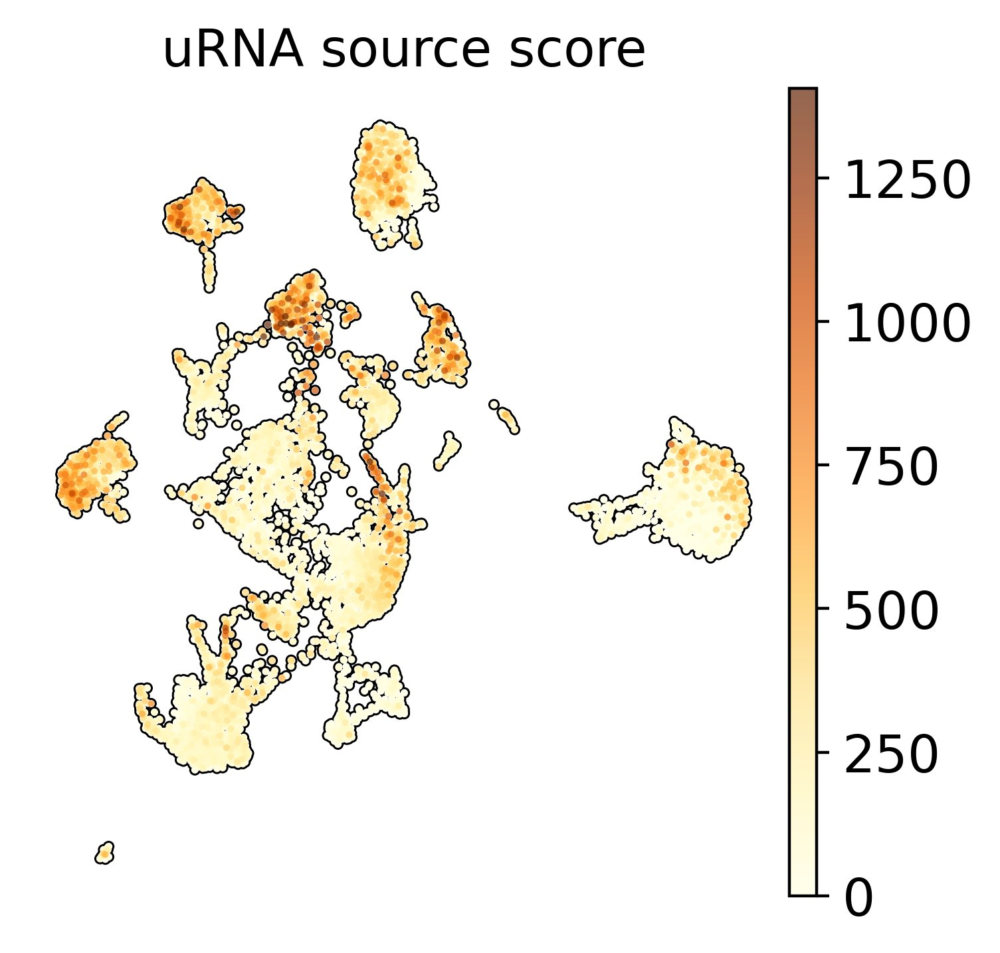

In [6]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_source_score',cmap='YlOrBr',add_outline=True,frameon=False,title='uRNA source score',show=False,vmax='p99.9')
plt.savefig(os.path.join(saving_path,'cells_umap_source_score.pdf'))

In [7]:
sdata['table'].obs['normalized_urna_source_score']=sdata['table'].obs['urna_source_score']/sdata['table'].obs['n_counts']

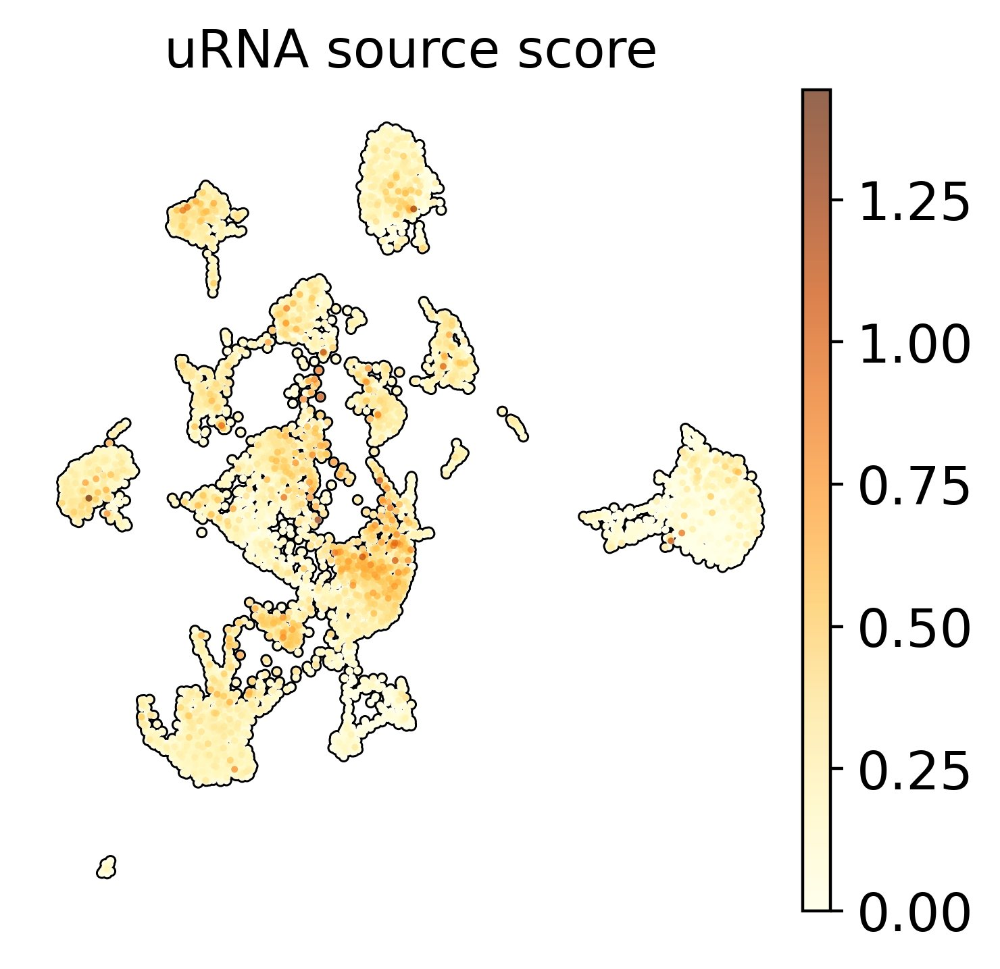

In [8]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='normalized_urna_source_score',cmap='YlOrBr',add_outline=True,frameon=False,title='uRNA source score',show=False,vmax='p99.995')
plt.savefig(os.path.join(saving_path,'cells_umap_source_score_norm.pdf'))

saving figure to file figures/show.pdf


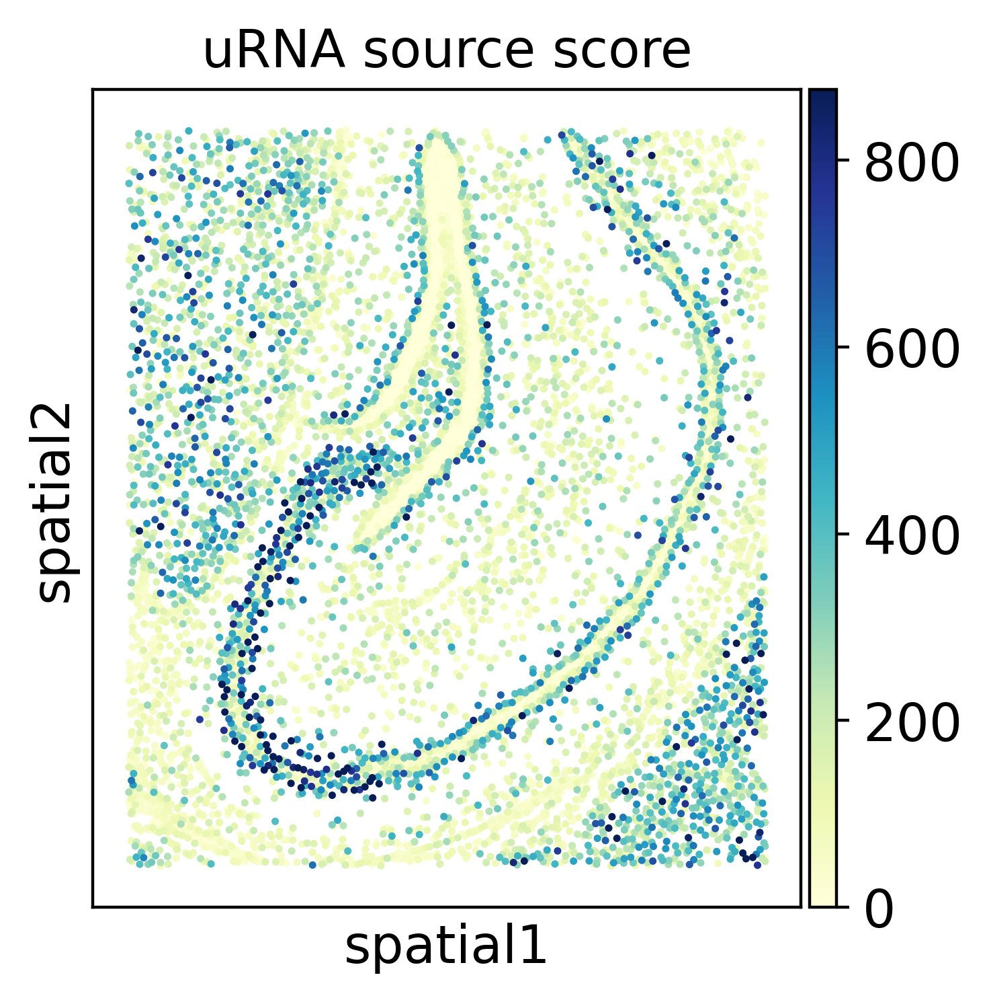

In [9]:
sc.pl.spatial(sdata['table'],color='urna_source_score',cmap='YlGnBu',spot_size=20,title='uRNA source score',save=True,vmax='p99')

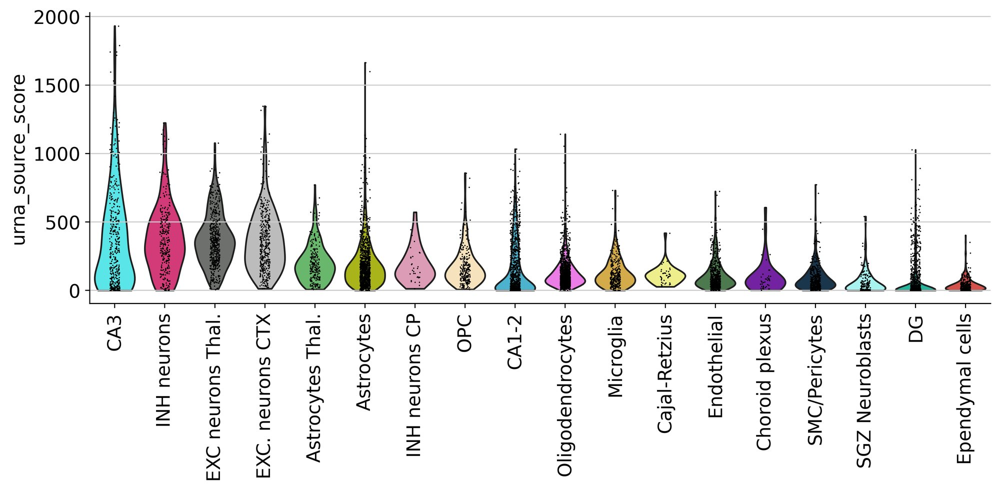

In [10]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_source_score',cell_type_key]].groupby(cell_type_key).mean().sort_values(by='urna_source_score',ascending=False).index
coldict=dict(zip(np.unique(sdata['table'].obs[cell_type_key]),sdata['table'].uns[cell_type_key+'_colors']))
cols=[coldict[o] for o in order_selected]

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_source_score',
    groupby=cell_type_key,
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_source_score.pdf'))


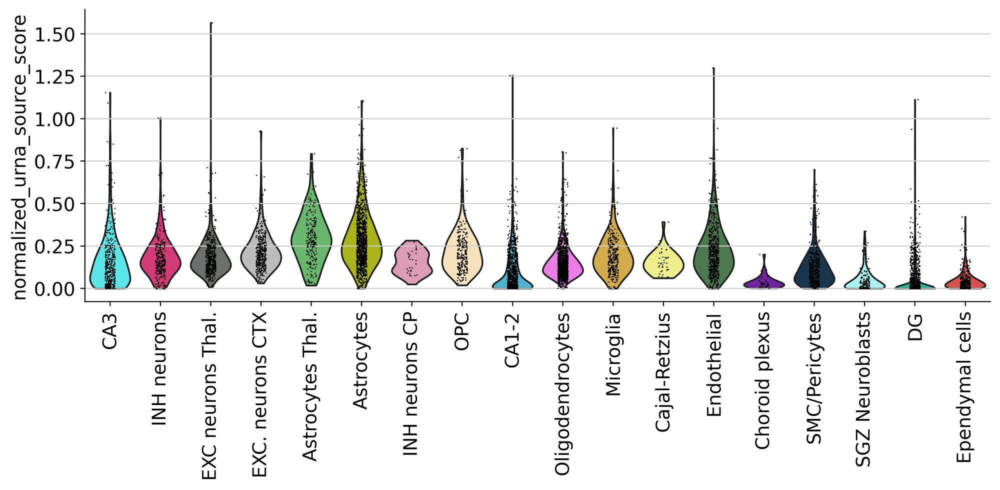

In [11]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_source_score',cell_type_key]].groupby(cell_type_key).mean().sort_values(by='urna_source_score',ascending=False).index
coldict=dict(zip(np.unique(sdata['table'].obs[cell_type_key]),sdata['table'].uns[cell_type_key+'_colors']))
cols=[coldict[o] for o in order_selected]

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'normalized_urna_source_score',
    groupby=cell_type_key,
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_normalized_source_score.pdf'))


# Identifying genes without a clear source

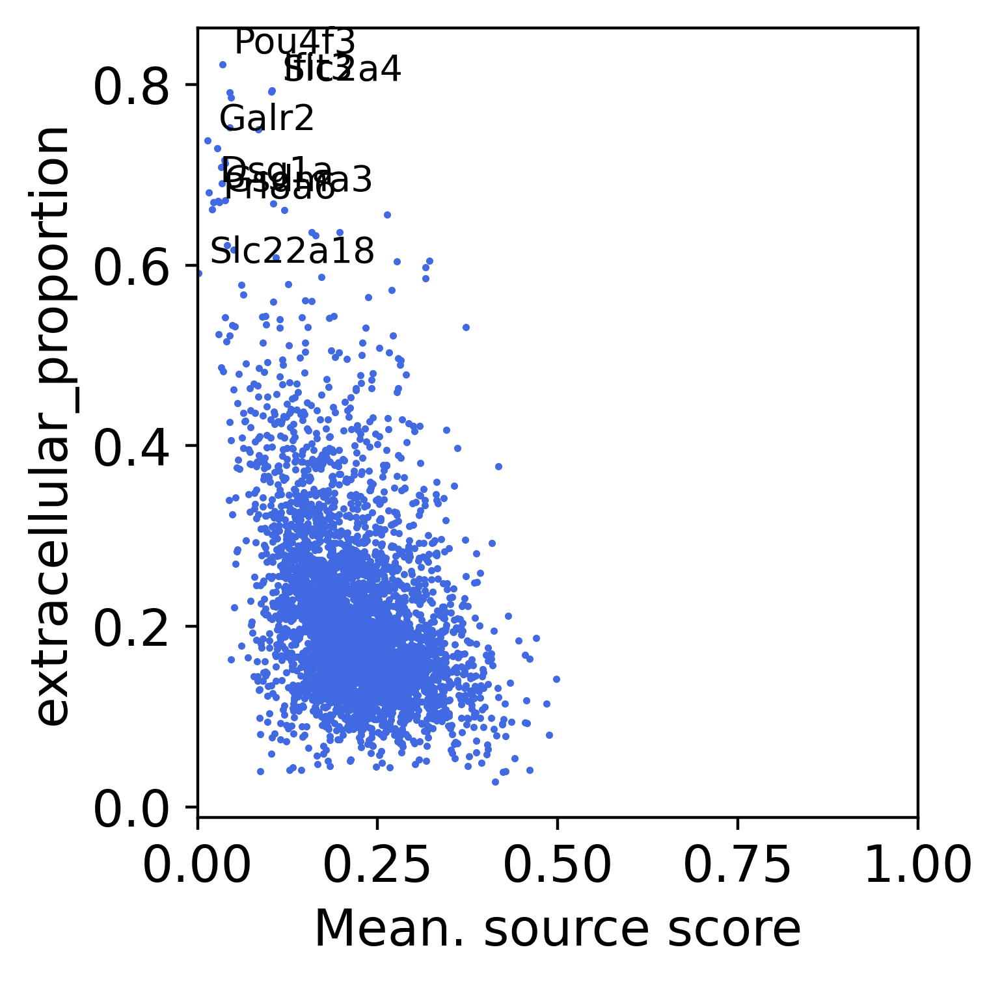

In [12]:
pl.urna_vs_source_score(
    sdata=sdata,
    y_var='extracellular_proportion',               # Your other variable from .var
    y_label='extracellular_proportion',        # Clean formatting for the plot axis
    saving_path=saving_path,
    bottom_x_genes=5,
    top_y_genes=3,
    lfc_thresh=2,
    color='royalblue',point_size=1,
    xlim=(0, 1),figsize=(4,4),
    ylim=None                           # Let it auto-scale for counts
)

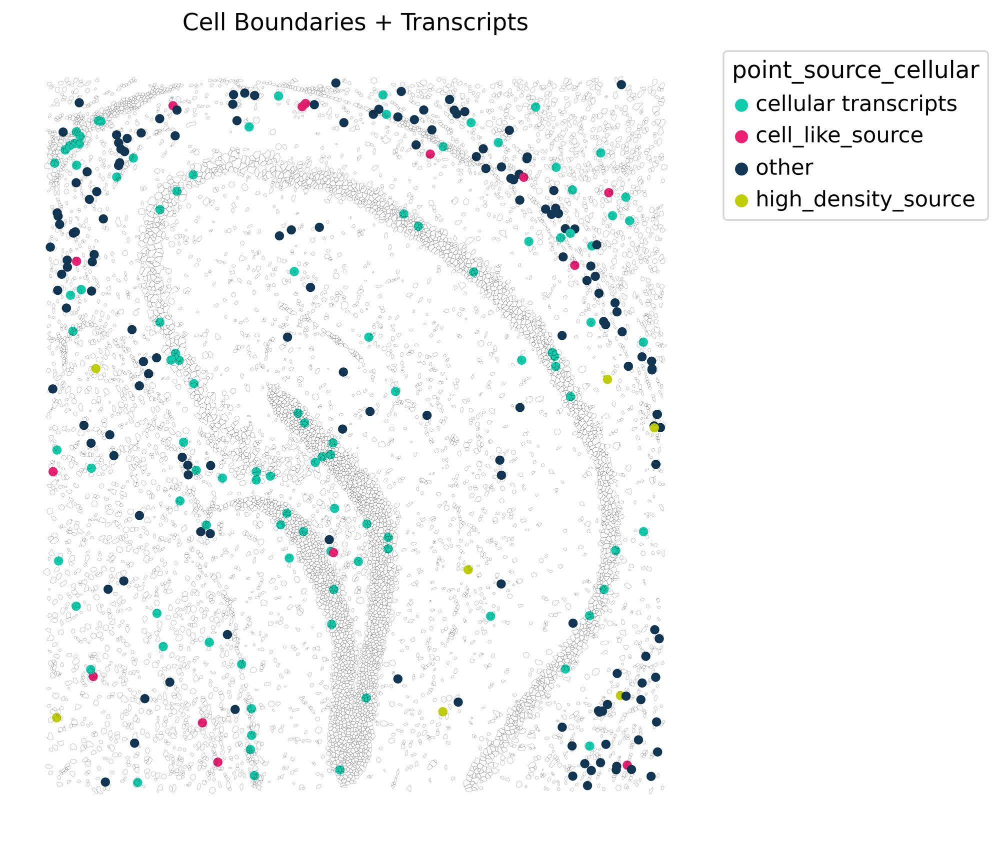

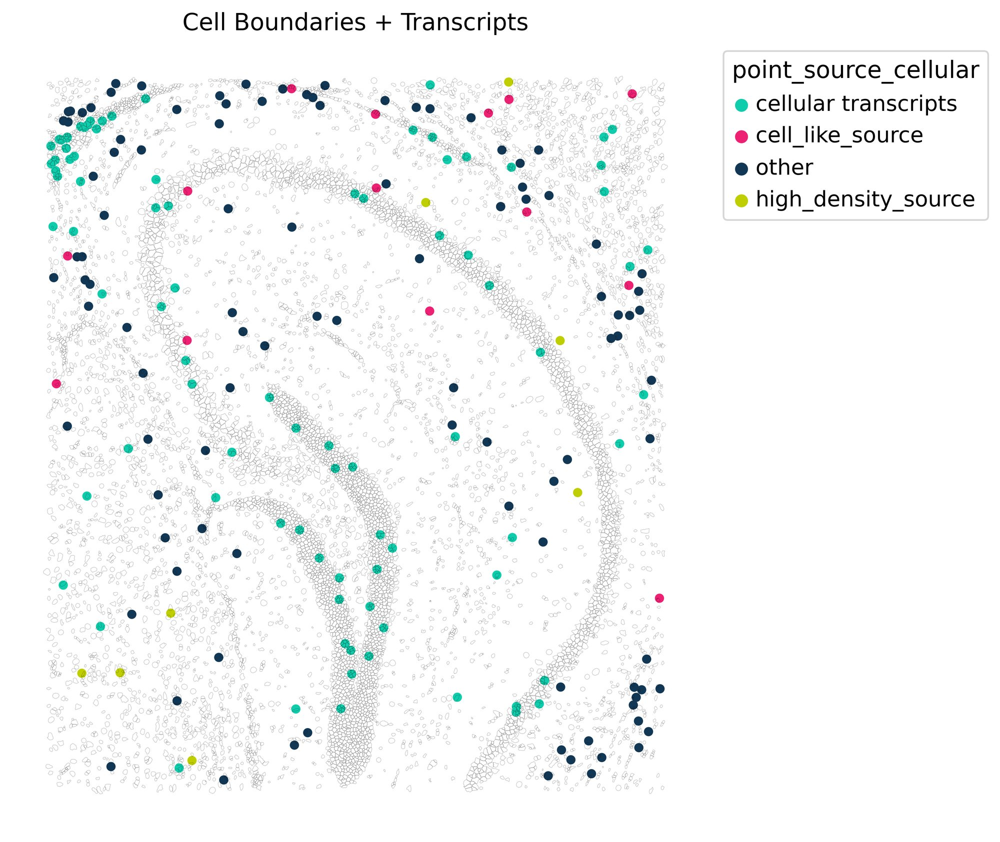

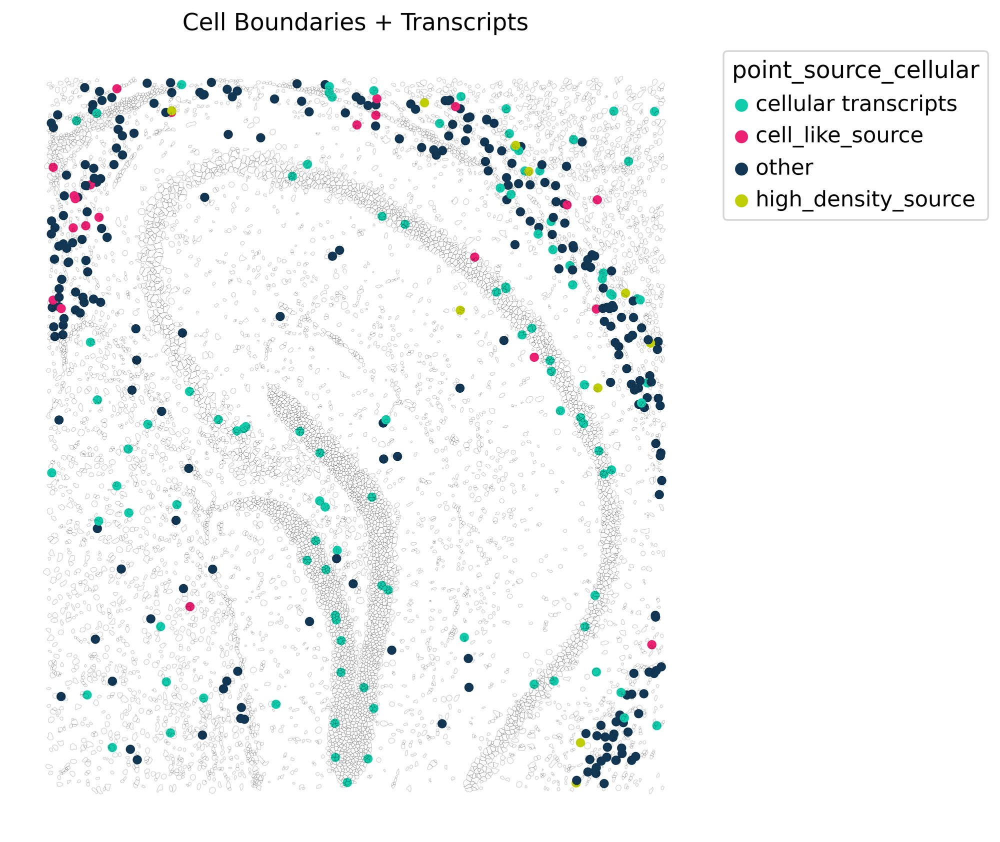

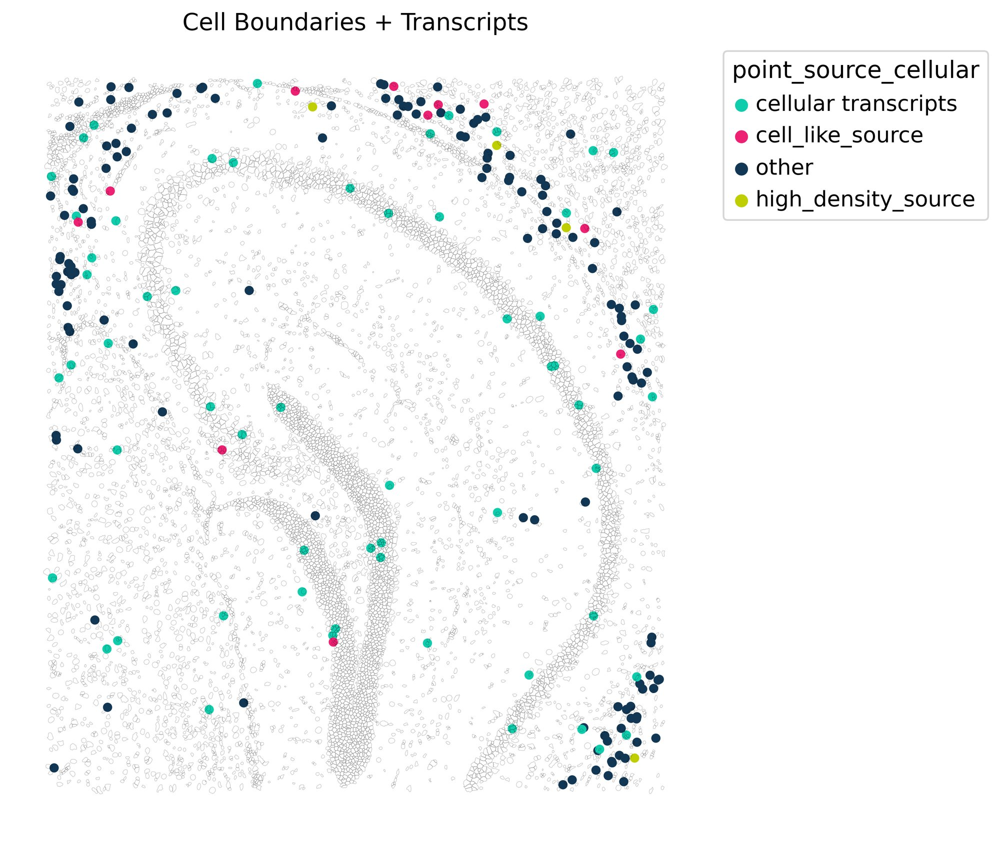

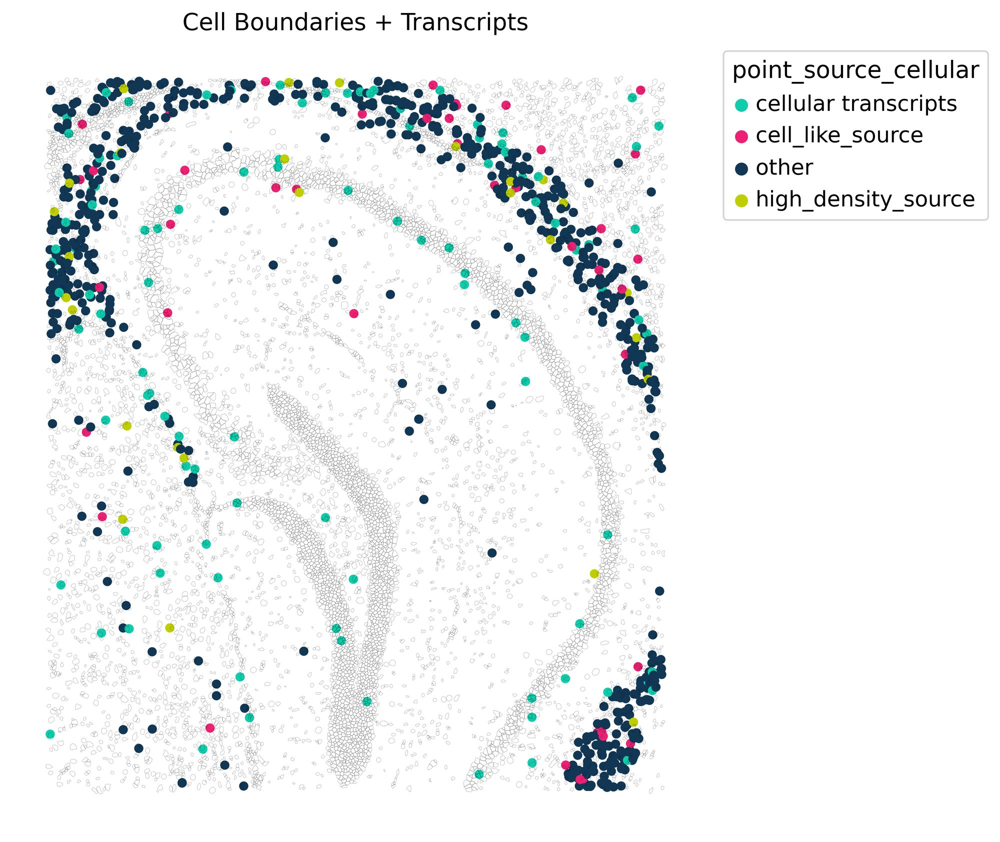

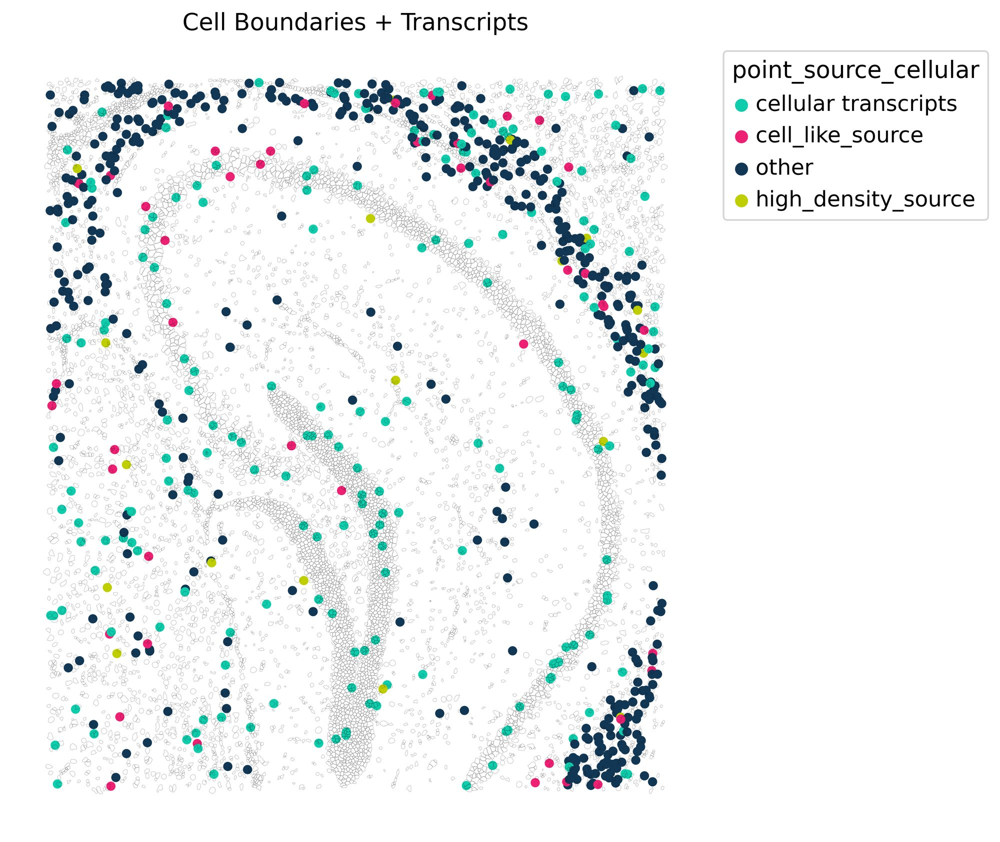

In [13]:
glist=['Slc22a18','Lhb','Dsg1a','Gsdma3','Pou4f3','Apoa4']
for g in glist:
    fig=pl.spatial_transcripts(sdata,gene_list=[g],scatter_size=20,boundary_linewidth=0.15)
    plt.savefig(os.path.join(saving_path,str(g)+'_spatial_transcripts_msbrain.pdf'))

# Spatial plot with source

(<Figure size 5000x5000 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels'}>)

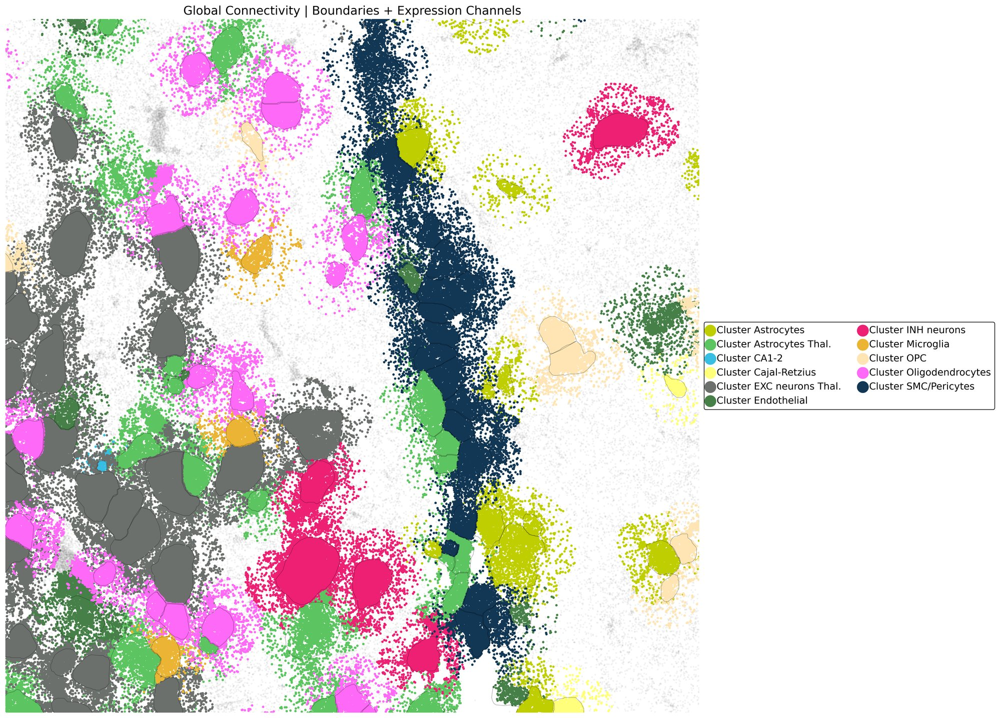

In [14]:
pl.spatial_transcripts_source(sdata,cell_color_key='cell_type',extra_color_key='cell_type',point_size=5,use_roi=True,roi=(4500, 4700, 1100, 1300),separate_compartments = False)

(<Figure size 5000x5000 with 1 Axes>,
 <Axes: title={'center': 'Global Connectivity | Boundaries + Expression Channels'}>)

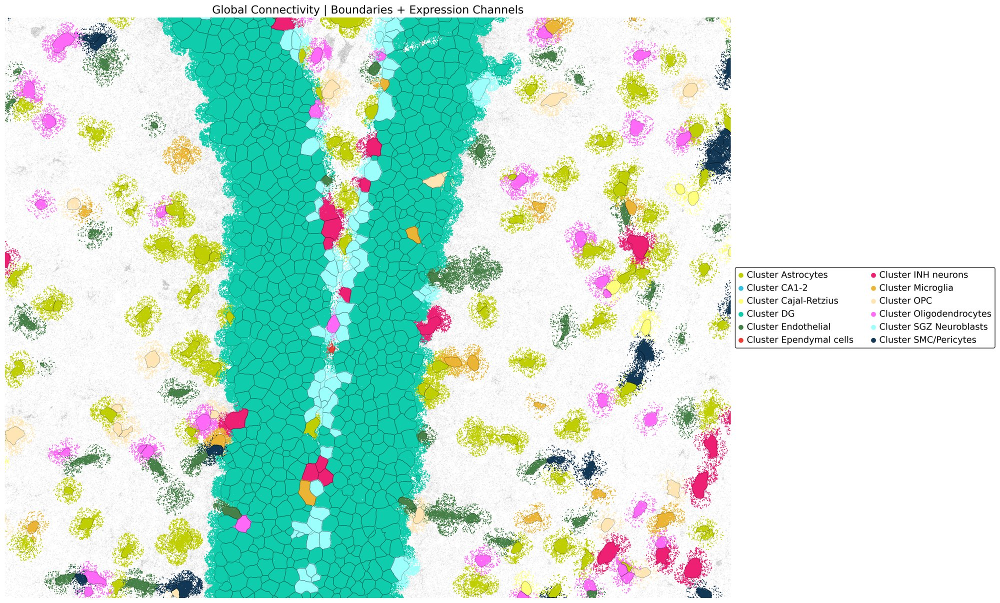

In [15]:
pl.spatial_transcripts_source(sdata,cell_color_key='cell_type',extra_color_key='cell_type',point_size=1,use_roi=True,roi=(4700, 5200, 1100, 1500),separate_compartments = False,min_score=0.2)

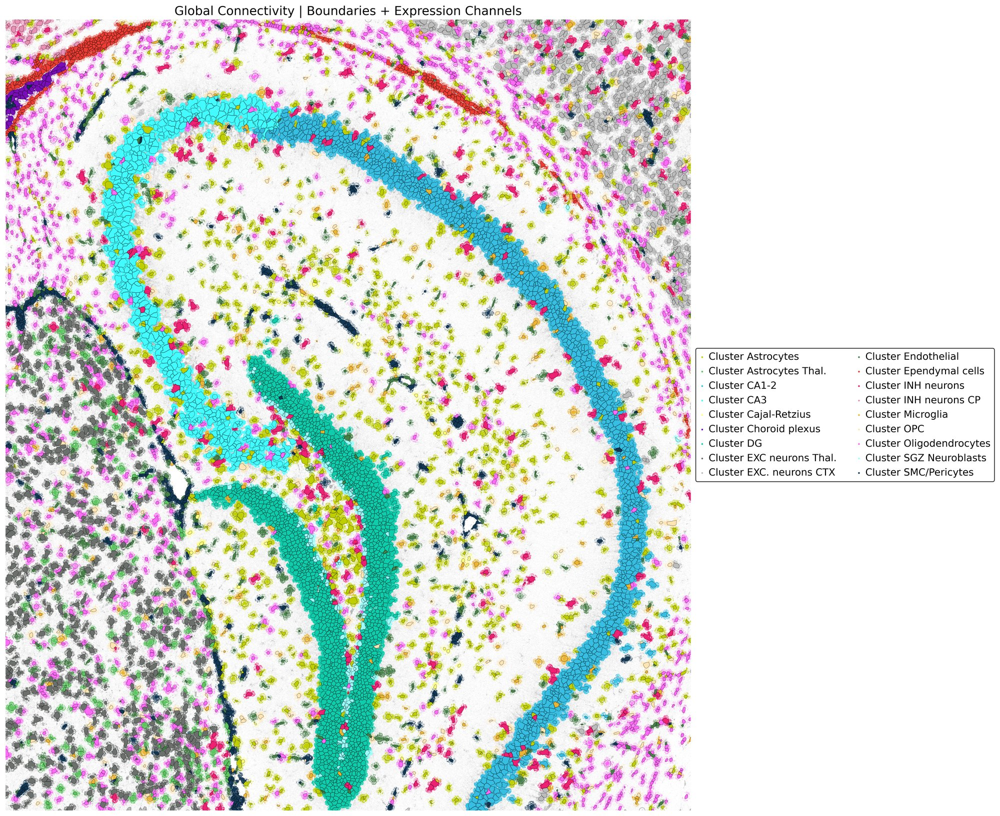

In [16]:
fig, ax = pl.spatial_transcripts_source(sdata,cell_color_key='cell_type',extra_color_key='cell_type',point_size=0.1,use_roi=False,separate_compartments = False,min_score=0.2)
# 1. Run the function and capture the figure object

# 2. Save the figure as a PNG
fig.savefig(
    os.path.join(saving_path,"full_spatial_transcripts_source_min02.png"), 
    dpi=300,                  # High resolution for publication-quality transcript points
    bbox_inches="tight",      # Ensures the legend on the right doesn't get cut off
    facecolor=fig.get_facecolor(), # Maintains your custom fig_bg_color background
    edgecolor="none"
)

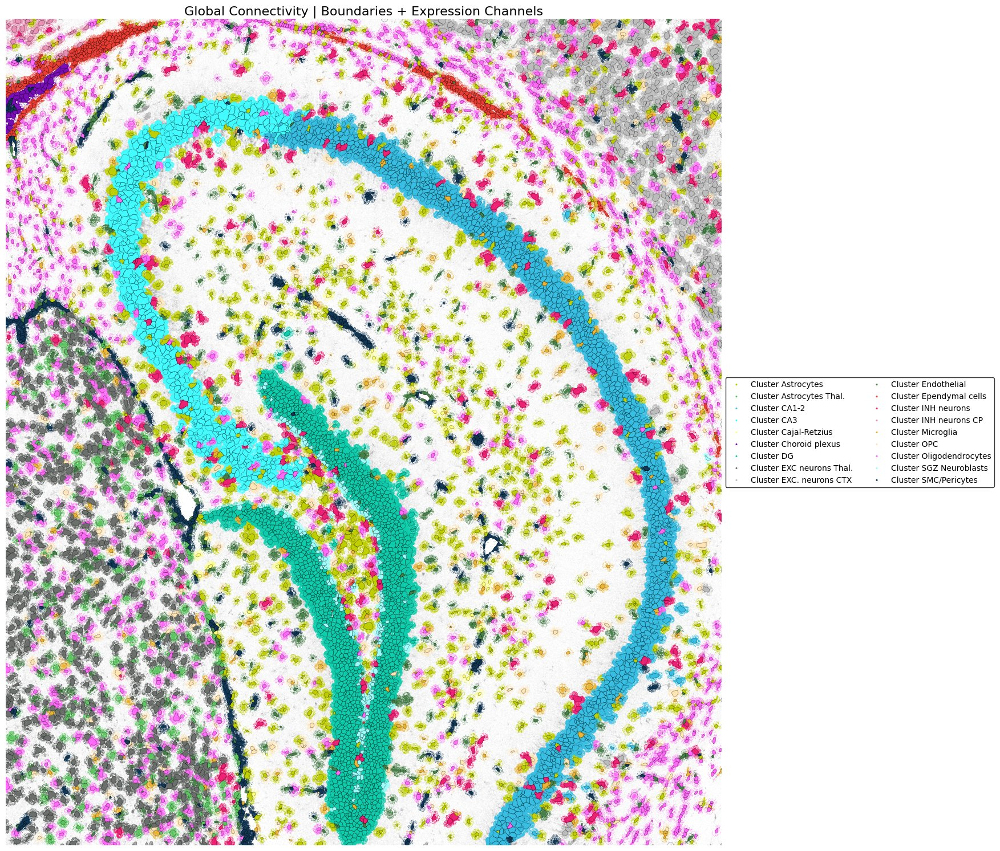

In [4]:
fig, ax = pl.spatial_transcripts_source(sdata,cell_color_key='cell_type',extra_color_key='cell_type',point_size=0.1,use_roi=False,separate_compartments = False,min_score=0.1)
fig.savefig(
    os.path.join(saving_path,"full_spatial_transcripts_source_min01.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

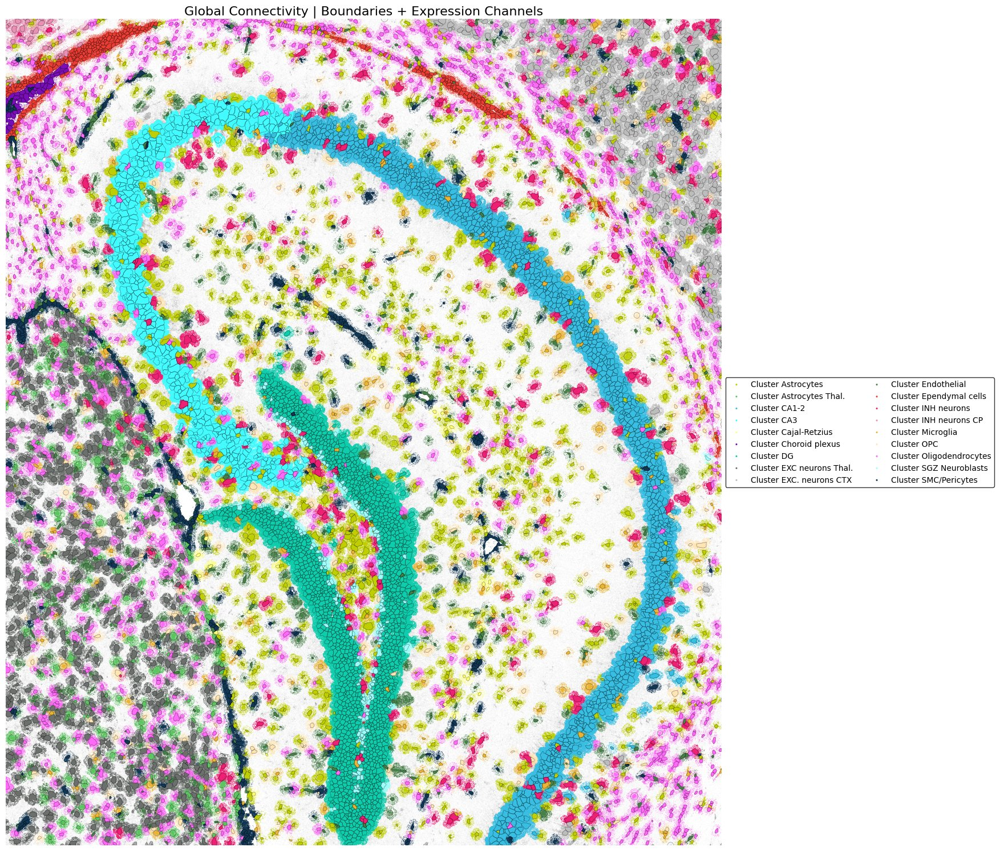

In [5]:
fig, ax = pl.spatial_transcripts_source(sdata,cell_color_key='cell_type',extra_color_key='cell_type',point_size=0.1,use_roi=False,separate_compartments = False,min_score=0.05)
fig.savefig(
    os.path.join(saving_path,"full_spatial_transcripts_source_min005.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

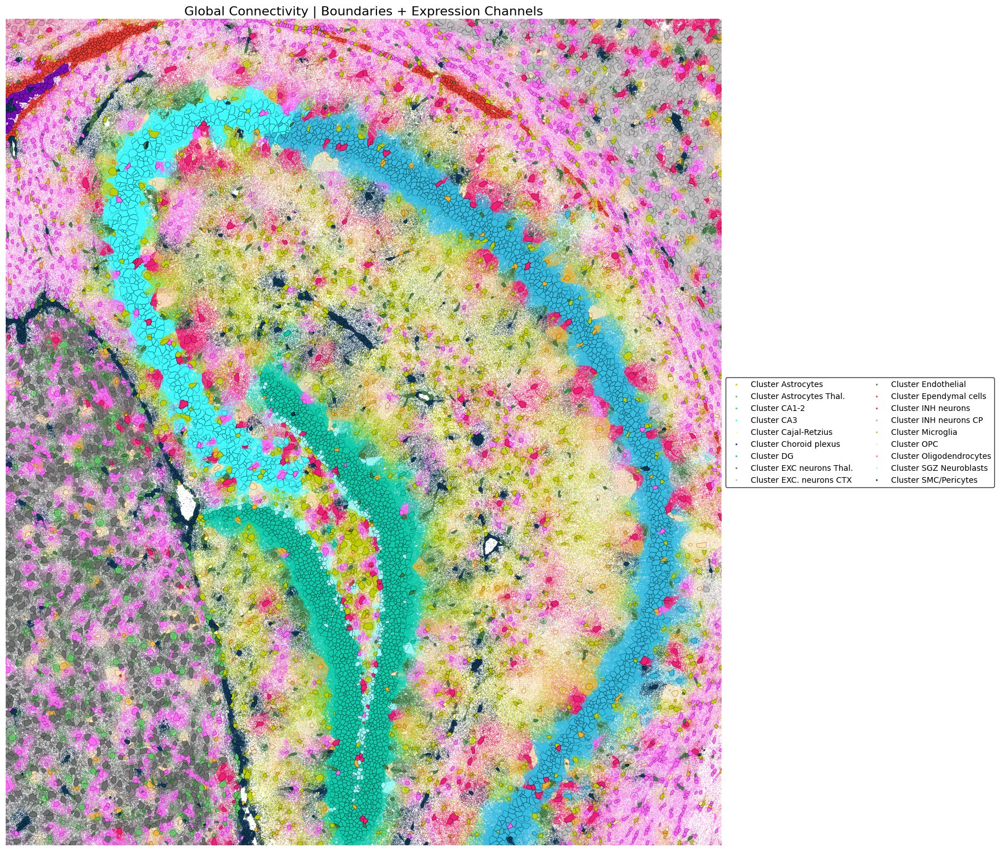

In [6]:
fig, ax = pl.spatial_transcripts_source(sdata,cell_color_key='cell_type',extra_color_key='cell_type',point_size=0.1,use_roi=False,separate_compartments = False,min_score=0)
fig.savefig(
    os.path.join(saving_path,"full_spatial_transcripts_source_min0.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor="none"
)

# RNA composition by cell type

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')
import scanpy as sc

### ==== TOOL FUNCTIONS ==== ###

def load_and_prepare_data(sdata):
    expr = sdata['table'].to_df()
    sdata['table'].X = sdata['table'].layers['raw'].todense()
    cell_types = sdata['table'].obs['cell_type']

    xrna_count = sdata['xrna_metadata'].var['count']
    contrib_df = sdata['source_score'].to_df()
    contrib_df['gene'] = sdata['source_score'].obs['gene']

    return expr, cell_types, xrna_count, contrib_df


def compute_contributions(contrib_df):
    contrib_matrix = contrib_df.groupby('gene').sum()
    contrib_norm = contrib_matrix  # optionally normalize here
    return contrib_norm


def compute_extracellular_counts(contrib_norm, xrna_count):
    genes_common = contrib_norm.index.intersection(xrna_count.index)
    return contrib_norm.loc[genes_common], xrna_count.loc[genes_common]


def compute_intracellular_counts(expr, cell_types):
    grouped = expr.groupby(cell_types)
    return grouped.sum().T, grouped.mean().T


def align_matrices(extra, intra, intra_mean):
    genes_final = extra.index.intersection(intra.index)
    celltypes_final = extra.columns.intersection(intra.columns)
    return (
        extra.loc[genes_final, celltypes_final],
        intra.loc[genes_final, celltypes_final],
        intra_mean.loc[genes_final, celltypes_final],
    )


def compute_extracellular_proportion(extra, intra):
    total = extra + intra
    return extra / total


def filter_genes(intra_mean):
    expr_frac = intra_mean.div(intra_mean.sum(axis=1), axis=0) > 0.1
    expr_level = intra_mean > 0.5
    return expr_frac & expr_level


def collect_filtered_data(extra_matrix, intra_matrix, intra_mean, prop_matrix, combined_filter):
    filtered = []
    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean[cell_type]
        filt = combined_filter[cell_type]
        prop = prop_matrix[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        for gene in extra.index:
            filtered.append({
                'gene': gene,
                'cell_type': cell_type,
                'extracellular_proportion': prop[gene]
            })
    return pd.DataFrame(filtered)
def compute_and_extrasomatic_proportion(
    sdata,
    source_score_key='source_score',
    expr_key='table',
    xrna_key='xrna_metadata',
    layer_key='raw',
    output_key='extrasomatic_proportion_x_cell_type'
):
    """
    Computes and stores extrasomatic (extracellular) proportion per gene per cell type into `sdata`.
    """

    # 1. Load data
    expr = sdata[expr_key].to_df()
    sdata[expr_key].X = sdata[expr_key].layers[layer_key].todense()
    cell_types = sdata[expr_key].obs['cell_type']

    xrna_count = sdata[xrna_key].var['count']
    contrib_df = sdata[source_score_key].to_df()
    contrib_df['gene'] = sdata[source_score_key].obs['gene']

    # 2. Compute contributions
    contrib_matrix = contrib_df.groupby('gene').sum()
    contrib_matrix = contrib_matrix.T.groupby(level=0).sum().T  # <-- NEW: collapse duplicate cell-type columns
    contrib_norm = contrib_matrix  # optional: normalize here if needed

    # 3. Compute extracellular counts
    genes_common = contrib_norm.index.intersection(xrna_count.index)
    extra_matrix = contrib_norm.loc[genes_common]
    xrna_count = xrna_count.loc[genes_common]

    # 4. Compute intracellular counts
    grouped = expr.groupby(cell_types)
    intra_matrix = grouped.sum().T
    intra_mean_matrix = grouped.mean().T

    # 5. Align all matrices
    genes_final = extra_matrix.index.intersection(intra_matrix.index)
    celltypes_final = extra_matrix.columns.intersection(intra_matrix.columns)

    extra_matrix = extra_matrix.loc[genes_final, celltypes_final]
    intra_matrix = intra_matrix.loc[genes_final, celltypes_final]
    intra_mean_matrix = intra_mean_matrix.loc[genes_final, celltypes_final]

    # 6. Compute extracellular proportion
    extracellular_proportion = extra_matrix / (extra_matrix + intra_matrix)

    # 7. Save result to AnnData
    extrasomatic_ct = sc.AnnData(extracellular_proportion.transpose())
    extrasomatic_ct.obs['cell_type'] = extrasomatic_ct.obs.index
    extrasomatic_ct.layers['extra_expression'] = extra_matrix.transpose()
    extrasomatic_ct.layers['intra_expression'] = intra_matrix.transpose()
    extrasomatic_ct.layers['intra_mean_expression'] = intra_mean_matrix.transpose()

    # 8. Store in sdata
    sdata[output_key] = extrasomatic_ct

    return sdata


### PLOTTING
import os
import matplotlib.pyplot as plt
import pandas as pd

def plot_extrasomatic_scatter_per_celltype(
    sdata,
    extrasomatic_key='extrasomatic_proportion_x_cell_type',
    min_expr_mean=0.5,
    min_expr_frac=0.1,
    figsize=(8, 6),
    s=10,
    color='magenta',
    fontsize=10,
    log_x=True,
    saving_path=None,
    save=False
):
    """
    Plots scatter plots per cell type for extracellular proportion vs intracellular expression.
    All data is extracted from `sdata` under the provided `extrasomatic_key`.

    Parameters
    ----------
    sdata : MuData
        Main data container.
    extrasomatic_key : str
        Key to access extrasomatic data (an AnnData) in sdata.
    min_expr_mean : float
        Minimum average intracellular expression to include gene.
    min_expr_frac : float
        Minimum expression fraction (relative) to include gene.
    figsize : tuple
        Figure size.
    s : float
        Size of the scatter plot points.
    color : str
        Color of scatter plot points.
    fontsize : int
        Font size for gene labels.
    log_x : bool
        Whether to apply log scale to x-axis.
    saving_path : str or None
        Path to save figures if `save` is True.
    save : bool
        Whether to save each plot as PDF.
    """

    extrasomatic = sdata[extrasomatic_key]

    # Ensure all matrices are DataFrames with proper labels
    extra_matrix = pd.DataFrame(
        extrasomatic.layers['extra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_matrix = pd.DataFrame(
        extrasomatic.layers['intra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_mean_matrix = pd.DataFrame(
        extrasomatic.layers['intra_mean_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    extracellular_proportion = pd.DataFrame(
        extrasomatic.X.T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    # Gene filtering
    gene_filter = (
        (intra_mean_matrix > min_expr_mean) &
        (intra_mean_matrix.div(intra_mean_matrix.sum(axis=1), axis=0) > min_expr_frac)
    )

    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean_matrix[cell_type]
        prop = extracellular_proportion[cell_type]
        filt = gene_filter[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        plt.figure(figsize=figsize)
        plt.scatter(intra_mean_col, prop, alpha=0.6, s=s, color=color)

        for gene, x, y in zip(extra.index, intra_mean_col, prop):
            plt.text(x, y, gene, fontsize=fontsize, alpha=0.7)

        plt.xlabel("Intracellular Expression")
        plt.ylabel("Extracellular Proportion")
        plt.title(f"Extracellular Enrichment in {cell_type}")
        plt.ylim(-0.05, 1.05)
        plt.grid(True, linestyle='--', alpha=0.5)
        if log_x:
            plt.xscale('log')
        plt.tight_layout()

        if save and saving_path:
            os.makedirs(saving_path, exist_ok=True)
            out_path = os.path.join(saving_path, f"scatter_{cell_type}_extrasomatic.pdf")
            plt.savefig(out_path)

        plt.show()

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib

def plot_violin_of_extrasomatic_proportion(
    sdata,
    extrasomatic_key='extrasomatic_proportion_x_cell_type',
    table_key='table',
    n=1,
    min_expr_mean=0.5,
    min_expr_frac=0.1,
    figsize=(7, 7),s=1,
    saving_path=None,
    save=False
):
    """
    Plot violin + stripplot of extracellular proportions per cell type from `sdata`.

    Parameters
    ----------
    sdata : MuData or dict-like
        Data structure containing the computed extracellular proportions.
    extrasomatic_key : str
        Key where the extrasomatic AnnData is stored in sdata.
    table_key : str
        Key for accessing cell type colors and cell type labels.
    n : int
        Number of top/bottom genes to annotate per cell type.
    min_expr_mean : float
        Minimum average intracellular expression to include gene.
    min_expr_frac : float
        Minimum fraction of expression per cell type to include gene.
    figsize : tuple
        Figure size for the plot.
    saving_path : str or None
        If provided and `save=True`, plot will be saved here.
    s: float
        Size of the dots in the stripplot
    save : bool
        Whether to save the plot to PDF.
    """

    extrasomatic = sdata[extrasomatic_key]

    # Ensure all layers and matrices are DataFrames with proper labels
    extra_matrix = pd.DataFrame(
        extrasomatic.layers['extra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_matrix = pd.DataFrame(
        extrasomatic.layers['intra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_mean_matrix = pd.DataFrame(
        extrasomatic.layers['intra_mean_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    extracellular_proportion = pd.DataFrame(
        extrasomatic.X.T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    # Apply filters
    gene_filter = (
        (intra_mean_matrix > min_expr_mean) &
        (intra_mean_matrix.div(intra_mean_matrix.sum(axis=1), axis=0) > min_expr_frac)
    )

    filtered_data = []
    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean_matrix[cell_type]
        prop = extracellular_proportion[cell_type]
        filt = gene_filter[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        for gene in extra.index:
            filtered_data.append({
                'gene': gene,
                'cell_type': cell_type,
                'extracellular_proportion': prop[gene]
            })

    filtered_df = pd.DataFrame(filtered_data)

    # Order cell types by mean extracellular proportion
    order_ct = (
        filtered_df
        .groupby('cell_type')['extracellular_proportion']
        .mean()
        .sort_values(ascending=False)
        .index
    )

    # Use color dictionary from sdata
    coldict = dict(zip(
        np.unique(sdata[table_key].obs['cell_type']),
        sdata[table_key].uns['cell_type_colors']
    ))
    cols = [coldict[c] for c in order_ct]

    # Plot
    # Set font type for vector output
    matplotlib.rcParams['pdf.fonttype'] = 42
    matplotlib.rcParams['ps.fonttype'] = 42
    plt.figure(figsize=figsize, dpi=100)
    ax = sns.violinplot(
        data=filtered_df,
        y='cell_type',
        x='extracellular_proportion',
        order=order_ct,
        alpha=0.8,
        linewidth=0,
        palette=cols,
        inner=None
    )

    sns.stripplot(
        data=filtered_df,
        y='cell_type',
        x='extracellular_proportion',
        color='gray',
        s=s,
        order=order_ct,
        jitter=0.3,
        linewidth=0.01,
        ax=ax
    )

    for cell_type in order_ct:
        df_sub = filtered_df[filtered_df['cell_type'] == cell_type]

        # Top n
        top_n = df_sub.nlargest(n, 'extracellular_proportion')
        for _, row in top_n.iterrows():
            ax.text(row['extracellular_proportion'], cell_type, row['gene'],
                    color='#bf1324', fontsize=10, va='bottom', ha='left')

        # Bottom n
        bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
        for _, row in bottom_n.iterrows():
            ax.text(row['extracellular_proportion'], cell_type, row['gene'],
                    color='#3d57ad', fontsize=10, va='bottom', ha='right')

    plt.xlabel('Extrasomatic Proportion')
    plt.ylabel('Cell Type')
    plt.tight_layout()

    if save and saving_path:
        os.makedirs(saving_path, exist_ok=True)
        out_path = os.path.join(saving_path, 'cells_extracellular_proportion.pdf')
        plt.savefig(out_path)

    plt.show()

In [18]:
sdata['table'].obs['cell_type'].unique()

['Oligodendrocytes', 'Microglia', 'Ependymal cells', 'EXC. neurons CTX', 'Choroid plexus', ..., 'Astrocytes', 'OPC', 'Cajal-Retzius', 'INH neurons CP', 'Astrocytes Thal.']
Length: 18
Categories (18, object): ['Astrocytes', 'Astrocytes Thal.', 'CA1-2', 'CA3', ..., 'OPC', 'Oligodendrocytes', 'SGZ Neuroblasts', 'SMC/Pericytes']

In [19]:
sdata['source_score']

AnnData object with n_obs × n_vars = 8388470 × 18
    obs: 'gene', 'predicted_parent', 'assignment_score', 'distance_to_source', 'sum_source_score'
    obsm: 'spatial'

In [20]:
sdata = compute_and_extrasomatic_proportion(sdata)

In [21]:
sdata

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k/data_annotated_lambda0.5.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 9300, 8049), (5, 4650, 4025), (5, 2325, 2012), (5, 1162, 1006), (5, 581, 502)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
│     └── 'nucleus_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 23) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 28) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (9289, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (9191, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (34056, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (9249, 1) (2D shapes)
└── T

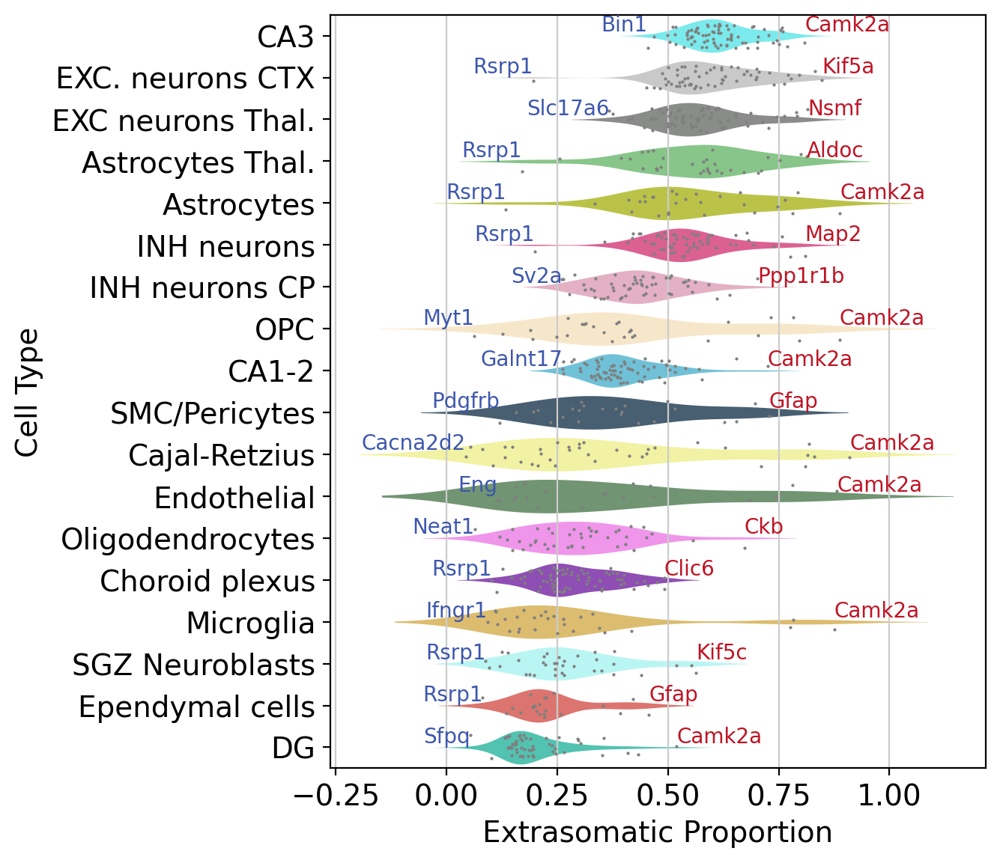

In [22]:
plot_violin_of_extrasomatic_proportion(
    sdata,
    n=1,
    min_expr_mean=1,
    min_expr_frac=0.05, s=1.5,
    figsize=(7, 6),
    saving_path=saving_path,
    save=True
)

# Compute communication

In [4]:
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy.sparse import lil_matrix, csr_matrix
from tqdm import tqdm


def celltype_contact_matrix(
    sdata,
    cell_type_key: str = "leiden",
    radius: float = 50.0,
    min_score: float = 0.1,
    gene_list: str | list[str] | None = None,
    gene_key: str = "gene",
    normalize: bool = False,
    cell_types: list[str] | None = None,
    tile_size: float = 1000.0,
    store_in_sdata: bool = False,         # save per-cell contacts into sdata['table']
    obsp_key: str = "transcript_contacts",  # key in sdata['table'].obsp
    obs_key: str = "contact_cell_ids",      # key in sdata['table'].obs
) -> pd.DataFrame:

    # ── 1. Load ───────────────────────────────────────────────────────────────
    cells       = sdata["table"]
    res_obs     = sdata.tables["source_score"].obs.copy()
    transcripts = sdata.points["transcripts"].compute()

    transcripts.index = transcripts.index.astype(int)
    res_obs.index     = res_obs.index.astype(int)

    # ── 2. Gene filter ────────────────────────────────────────────────────────
    if gene_list is not None:
        if isinstance(gene_list, str):
            gene_list = [gene_list]
        transcripts = transcripts[transcripts[gene_key].isin(gene_list)].copy()
        if transcripts.empty:
            print(f"No transcripts found for gene(s): {gene_list}")
            return pd.DataFrame()

    # ── 3. Cell type map + cell integer index (needed for obsp) ──────────────
    cell_obs = cells.obs.copy()
    cell_obs["cell_id"] = cell_obs["cell_id"].astype(str).str.strip()
    cell_type_map = dict(zip(cell_obs["cell_id"], cell_obs[cell_type_key].astype(str)))

    # Get the official category ordering and colors from sdata['table']
    if isinstance(cells.obs[cell_type_key].dtype, pd.CategoricalDtype):
        official_categories = list(cells.obs[cell_type_key].cat.categories)
    else:
        official_categories = sorted(cells.obs[cell_type_key].unique().astype(str))

    # Fetch colors if they exist in .uns
    uns_colors_key = f"{cell_type_key}_colors"
    color_map = {}
    if uns_colors_key in cells.uns:
        colors = cells.uns[uns_colors_key]
        color_map = dict(zip(official_categories, colors))

    # Integer position of each cell_id in sdata['table'].obs (for obsp matrix)
    cell_id_to_idx = {cid: i for i, cid in enumerate(cell_obs["cell_id"])}
    n_cells = len(cell_obs)

    allowed = set(cell_types) if cell_types is not None else None

    # ── 4. Vectorized owner assignment ───────────────────────────────────────
    print("Assigning transcript owners...")
    transcripts = transcripts.join(
        res_obs[["predicted_parent", "assignment_score"]], how="left"
    )
    transcripts["cell_id_str"]        = transcripts["cell_id"].astype(str).str.strip()
    transcripts["parent_id_str"]      = transcripts["predicted_parent"].astype(str).str.strip()
    transcripts["overlaps_cell_bool"] = transcripts["overlaps_cell"].astype(str).str.lower() == "true"

    is_body = transcripts["overlaps_cell_bool"] & transcripts["cell_id_str"].isin(cell_type_map)
    is_halo = (
        ~transcripts["overlaps_cell_bool"]
        & (transcripts["assignment_score"] >= min_score)
        & transcripts["parent_id_str"].isin(cell_type_map)
    )

    transcripts["owner"] = np.where(
        is_body, transcripts["cell_id_str"],
        np.where(is_halo, transcripts["parent_id_str"], np.nan)
    )

    owned = transcripts[transcripts["owner"].notna()].copy()
    if allowed is not None:
        owned = owned[owned["owner"].map(cell_type_map).isin(allowed)]

    coords = owned[["x", "y"]].values
    owners = owned["owner"].values

    print(f"Owned transcripts: {len(owned):,} / {len(transcripts):,} total")

    # ── 5. Tiled query_pairs ──────────────────────────────────────────────────
    x_min, x_max = coords[:, 0].min(), coords[:, 0].max()
    y_min, y_max = coords[:, 1].min(), coords[:, 1].max()

    x_starts = np.arange(x_min, x_max, tile_size)
    y_starts = np.arange(y_min, y_max, tile_size)
    tiles    = [(x0, y0) for x0 in x_starts for y0 in y_starts]

    all_cell_pairs = set()   # (cell_id_a, cell_id_b) directed

    # Sparse adjacency matrix built incrementally (only if storing)
    if store_in_sdata:
        adj = lil_matrix((n_cells, n_cells), dtype=np.int8)

    for x0, y0 in tqdm(tiles, desc="Processing tiles", unit="tile",
                       postfix={"grid": f"{len(x_starts)}x{len(y_starts)}",
                                "cell_pairs": 0}):
        x1 = x0 + tile_size
        y1 = y0 + tile_size

        mask = (
            (coords[:, 0] >= x0 - radius) & (coords[:, 0] < x1 + radius) &
            (coords[:, 1] >= y0 - radius) & (coords[:, 1] < y1 + radius)
        )
        tile_coords = coords[mask]
        tile_owners = owners[mask]

        if len(tile_coords) < 2:
            continue

        tree  = cKDTree(tile_coords)
        pairs = tree.query_pairs(r=radius, output_type="ndarray")

        if len(pairs) == 0:
            continue

        sc = tile_owners[pairs[:, 0]]
        nc = tile_owners[pairs[:, 1]]

        diff = sc != nc
        sc, nc = sc[diff], nc[diff]

        if len(sc) == 0:
            continue

        for a, b in zip(sc, nc):
            all_cell_pairs.add((a, b))
            all_cell_pairs.add((b, a))

In [4]:
owned_estimate = sdata.points["transcripts"].compute()
owned_estimate = owned_estimate[owned_estimate["overlaps_cell"].astype(str).str.lower() == "true"]

coords = owned_estimate[["x", "y"]].values
x_range = coords[:, 0].max() - coords[:, 0].min()
y_range = coords[:, 1].max() - coords[:, 1].min()
density = len(owned_estimate) / (x_range * y_range)
tile_size = np.sqrt(30_000 / density)
print(f"Suggested tile_size: {tile_size:.1f}")

_mat_cache_path = os.path.join(saving_path, "_cache_mat_r5.csv")
if os.path.exists(_mat_cache_path):
    mat = pd.read_csv(_mat_cache_path, index_col=0)
    print(f"Loaded cached contact matrix from {_mat_cache_path}")
else:
    mat = tl.celltype_contact_matrix(sdata, tile_size=tile_size,radius=5,cell_type_key="cell_type")
    mat.to_csv(_mat_cache_path)

# celltype_contact_matrix only returns cell types that appear in at least one
# detected cross-type contact pair - reindex to the full category list so rarer
# types with zero contacts still show up (as all-zero rows/cols) in the heatmap.
all_cell_types = sorted(sdata["table"].obs["cell_type"].unique())
mat = mat.reindex(index=all_cell_types, columns=all_cell_types, fill_value=0)

Suggested tile_size: 81.0
Loaded cached contact matrix from /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/_cache_mat_r5.csv


In [5]:
_mat_intracell_cache_path = os.path.join(saving_path, "_cache_mat_intracell_r5.csv")
if os.path.exists(_mat_intracell_cache_path):
    mat_intracell = pd.read_csv(_mat_intracell_cache_path, index_col=0)
    print(f"Loaded cached contact matrix from {_mat_intracell_cache_path}")
else:
    mat_intracell = tl.celltype_contact_matrix(sdata, tile_size=tile_size,cell_type_key='cell_type',radius=5,min_score = 1.0, store_in_sdata=False)
    mat_intracell.to_csv(_mat_intracell_cache_path)

all_cell_types = sorted(sdata["table"].obs["cell_type"].unique())
mat_intracell = mat_intracell.reindex(index=all_cell_types, columns=all_cell_types, fill_value=0)

Assigning transcript owners...


Owned transcripts: 15,402,286 / 23,790,756 total


Processing tiles (22x25 grid):   0%|          | 0/550 [00:00<?, ?tile/s]

Processing tiles (22x25 grid):   0%|          | 1/550 [00:01<15:48,  1.73s/tile]

Processing tiles (22x25 grid):   0%|          | 2/550 [00:02<12:22,  1.35s/tile]

...

Processing tiles (22x25 grid): 100%|█████████▉| 549/550 [29:23<00:00,  1.86tile/s]

Processing tiles (22x25 grid): 100%|██████████| 550/550 [29:23<00:00,  2.11tile/s]

Processing tiles (22x25 grid): 100%|██████████| 550/550 [29:23<00:00,  3.21s/tile]

Unique directed cell-cell contacts found: 36,578
Building contact matrix...


Done.


In [26]:
mat = tl.celltype_contact_matrix(sdata, tile_size=tile_size,radius=5,cell_type_key='cell_type',store_in_sdata=True)

Assigning transcript owners...


Owned transcripts: 19,231,845 / 23,790,756 total


Processing tiles (22x25 grid):   0%|          | 0/550 [00:00<?, ?tile/s]

Processing tiles (22x25 grid):   0%|          | 1/550 [00:16<2:26:30, 16.01s/tile]

Processing tiles (22x25 grid):   0%|          | 2/550 [00:21<1:29:33,  9.81s/tile]

...

Processing tiles (22x25 grid):  98%|█████████▊| 539/550 [8:44:55<00:27,  2.52s/tile]

Processing tiles (22x25 grid):  99%|█████████▊| 543/550 [8:45:29<00:48,  6.92s/tile]

Processing tiles (22x25 grid):  99%|█████████▉| 547/550 [8:45:48<00:14,  4.85s/tile]

Processing tiles (22x25 grid): 100%|██████████| 550/550 [8:46:12<00:00, 57.40s/tile]

Done.


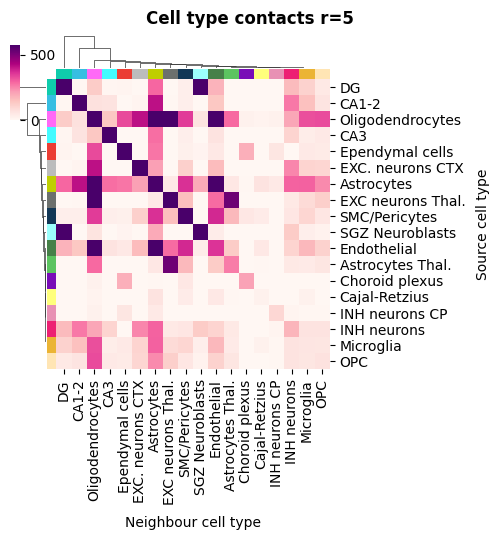

In [6]:
# Clustered heatmap with uns colors
g = pl.celltype_contact_matrix(mat, sdata=sdata, kind="heatmap", title="Cell type contacts r=5",cell_type_key='cell_type',figsize=(5,5),cmap='RdPu',vmax=np.percentile(mat.values, 95))
g.savefig(os.path.join(saving_path,'heatmap_cell_type_contacts_r5.pdf'))

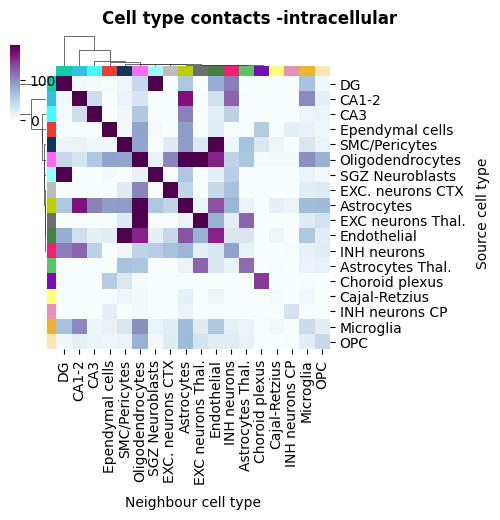

In [7]:
# Clustered heatmap with uns colors
g = pl.celltype_contact_matrix(mat_intracell, sdata=sdata, kind="heatmap", title="Cell type contacts -intracellular",cell_type_key='cell_type',figsize=(5,5),cmap='BuPu',vmax=np.percentile(mat_intracell.values, 95))
g.savefig(os.path.join(saving_path,'heatmap_cell_type_contacts_intracelular.pdf'))

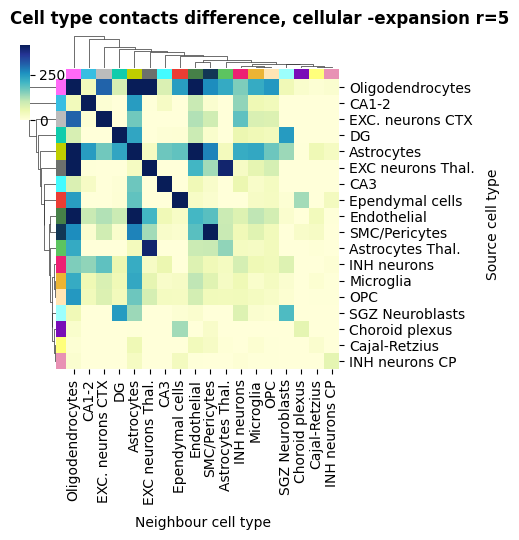

In [8]:
# Clustered heatmap with uns colors
contact_diff = mat - mat_intracell
g = pl.celltype_contact_matrix(contact_diff, sdata=sdata, kind="heatmap", cmap='YlGnBu',title="Cell type contacts difference, cellular -expansion r=5",cell_type_key='cell_type',figsize=(5,5),vmax=np.percentile(contact_diff.values, 95))
g.savefig(os.path.join(saving_path,'heatmap_cell_type_difference_intracellular.pdf'))

# OPC contacts: cell body vs. protrusion-mediated (10 µm)

Two ways an OPC can be "in contact" with a neighbouring cell, both using a 10 µm contact distance:

- **Cell body contact** – the OPC segmentation polygon lies within 10 µm of the partner's segmentation polygon (body-to-body, no uRNA involved).
- **Protrusion contact** – an OPC protrusion transcript lies within 10 µm of the partner's polygon. Protrusion transcripts = transcripts outside any segmented cell (`overlaps_cell == False`) whose `predicted_parent` is an OPC with `assignment_score >= 0.1` (same `min_score` as the r=5 contact matrix above).
- **Protrusion-only contact** – partners reached through protrusions that are *not* already body contacts, i.e. the contacts that protrusions add on top of the cell body.

Cell polygons are used in their stored (µm) coordinates: they already match the transcript frame (mean area ~80 µm², centroids match `obsm['spatial']`), so the `Scale(4.71)` transform attached to `cell_boundaries` is not applied.

In [4]:
from tqdm import tqdm
import shapely
from shapely import STRtree


def load_extracellular_assignments(sdata):
    """Transcripts outside segmented cells, with their predicted parent cell and assignment score."""
    tx = sdata.points["transcripts"][["x", "y", "overlaps_cell"]].compute()
    tx = tx[tx["overlaps_cell"].astype(str).str.lower() != "true"]
    res = sdata.tables["source_score"].obs[["predicted_parent", "assignment_score"]].copy()
    tx.index = tx.index.astype(int)
    res.index = res.index.astype(int)
    tx = tx.join(res, how="inner")
    tx["parent"] = tx["predicted_parent"].astype(str).str.strip()
    return tx[["x", "y", "parent", "assignment_score"]]


def focal_celltype_contacts(
    sdata,
    focal_type: str = "OPC",
    cell_type_key: str = "cell_type",
    contact_dist: float = 10.0,
    min_score: float = 0.1,
    min_protrusion_tx: int = 1,
    shapes_key: str = "cell_boundaries",
    extra_tx: pd.DataFrame | None = None,  # output of load_extracellular_assignments (reused across calls)
    verbose: bool = True,
):
    """Per-pair contacts of `focal_type` cells, split into body and protrusion-mediated.

    Returns a DataFrame with one row per (focal cell, partner cell) pair and boolean
    columns `body` / `protrusion`, plus the number of focal protrusion transcripts
    within `contact_dist` of the partner, and the per-focal-cell protrusion transcript count.
    """
    obs = sdata["table"].obs.copy()
    obs["cell_id"] = obs["cell_id"].astype(str).str.strip()
    ct_map = dict(zip(obs["cell_id"], obs[cell_type_key].astype(str)))

    # Only annotated cells; polygon coords are already in the transcript (µm) frame
    polys = sdata.shapes[shapes_key]
    polys = polys[polys.index.isin(list(ct_map))]
    poly_ids = polys.index.to_numpy().astype(str)
    poly_types = np.array([ct_map[c] for c in poly_ids])
    geoms = polys.geometry.values
    tree = STRtree(geoms)

    focal_pos = np.where(poly_types == focal_type)[0]
    if verbose:
        print(f"{focal_type} cells with a polygon: {len(focal_pos)}")

    # ── 1. Cell body contacts: polygon-to-polygon distance <= contact_dist ──
    q, t = tree.query(geoms[focal_pos], predicate="dwithin", distance=contact_dist)
    body = pd.DataFrame({"focal_id": poly_ids[focal_pos][q], "partner_id": poly_ids[t]})
    body = body[body["focal_id"] != body["partner_id"]].drop_duplicates()
    body["body"] = True

    # ── 2. Protrusion transcripts of the focal cells ────────────────────────
    tx = load_extracellular_assignments(sdata) if extra_tx is None else extra_tx
    is_focal_parent = tx["parent"].map(ct_map).eq(focal_type)
    prot = tx[is_focal_parent & (tx["assignment_score"] >= min_score)]
    if verbose:
        print(f"{focal_type} protrusion transcripts (score >= {min_score}): {len(prot):,}")

    # ── 3. Protrusion contacts: protrusion transcript within contact_dist of a polygon ──
    pts = shapely.points(prot[["x", "y"]].to_numpy())
    q, t = tree.query(pts, predicate="dwithin", distance=contact_dist)
    pr = pd.DataFrame({"focal_id": prot["parent"].to_numpy()[q], "partner_id": poly_ids[t]})
    pr = pr[pr["focal_id"] != pr["partner_id"]]
    pr = pr.groupby(["focal_id", "partner_id"]).size().rename("n_protrusion_tx").reset_index()
    pr = pr[pr["n_protrusion_tx"] >= min_protrusion_tx]
    pr["protrusion"] = True

    pairs = body.merge(pr, on=["focal_id", "partner_id"], how="outer")
    pairs["body"] = pairs["body"].fillna(False).astype(bool)
    pairs["protrusion"] = pairs["protrusion"].fillna(False).astype(bool)
    pairs["n_protrusion_tx"] = pairs["n_protrusion_tx"].fillna(0).astype(int)
    pairs["partner_type"] = pairs["partner_id"].map(ct_map)
    pairs["mode"] = np.select(
        [pairs["body"] & ~pairs["protrusion"], pairs["body"] & pairs["protrusion"]],
        ["body_only", "body_and_protrusion"],
        default="protrusion_only",
    )

    n_prot_per_focal = prot["parent"].value_counts()
    focal_ids = poly_ids[focal_pos]
    focal_prot = pd.Series(n_prot_per_focal.reindex(focal_ids).fillna(0).astype(int).to_numpy(),
                           index=focal_ids, name="n_protrusion_tx")
    return pairs, focal_prot, prot


def summarize_focal_contacts(pairs, focal_ids, obs, cell_type_key="cell_type", focal_type="OPC"):
    """Per partner cell type: pair counts, fraction of focal cells in contact, and enrichment.

    Enrichment = (share of contacts going to type T) / (share of type T among all
    annotated cells, excluding the focal cell itself), reported as log2.
    """
    all_types = sorted(obs[cell_type_key].astype(str).unique())
    n_focal = len(focal_ids)
    comp = obs[cell_type_key].astype(str).value_counts().reindex(all_types, fill_value=0).astype(float)
    comp[focal_type] -= 1  # a cell can't contact itself
    expected_share = comp / comp.sum()

    body = pairs[pairs["body"]]
    prot = pairs[pairs["protrusion"]]
    prot_only = pairs[pairs["mode"] == "protrusion_only"]
    any_ = pairs

    def n_pairs(df):
        return df.groupby("partner_type").size().reindex(all_types, fill_value=0)

    def frac_focal(df):
        return df.groupby("partner_type")["focal_id"].nunique().reindex(all_types, fill_value=0) / n_focal

    def log2_enrich(df):
        # NaN (not -inf) where a type has no contacts of that kind
        share = n_pairs(df).replace(0, np.nan) / max(len(df), 1)
        return np.log2(share / expected_share)

    summary = pd.DataFrame({
        "n_cells_of_type": comp.astype(int),
        "pairs_body": n_pairs(body),
        "pairs_protrusion": n_pairs(prot),
        "pairs_protrusion_only": n_pairs(prot_only),
        "pairs_total": n_pairs(any_),
        "frac_focal_body": frac_focal(body),
        "frac_focal_protrusion": frac_focal(prot),
        "frac_focal_total": frac_focal(any_),
        "log2_enrich_body": log2_enrich(body),
        "log2_enrich_protrusion_only": log2_enrich(prot_only),
    })
    summary["protrusion_gain"] = summary["pairs_total"] / summary["pairs_body"].replace(0, np.nan)
    summary.index.name = "partner_type"
    return summary.sort_values("pairs_total", ascending=False)

In [5]:
OPC_CONTACT_DIST = 10.0  # µm
extra_tx = load_extracellular_assignments(sdata)
opc_pairs, opc_prot_tx, opc_prot_points = focal_celltype_contacts(
    sdata, focal_type="OPC", cell_type_key="cell_type", extra_tx=extra_tx,
    contact_dist=OPC_CONTACT_DIST, min_score=0.1, min_protrusion_tx=1,
)
opc_summary = summarize_focal_contacts(opc_pairs, opc_prot_tx.index, sdata["table"].obs, cell_type_key="cell_type", focal_type="OPC")

opc_pairs.to_csv(os.path.join(saving_path, "opc_contacts_pairs_10um.csv"), index=False)
opc_summary.to_csv(os.path.join(saving_path, "opc_contacts_summary_10um.csv"))

n_opc = len(opc_prot_tx)
print(f"\nOPCs: {n_opc} | OPCs with >=1 protrusion transcript: {(opc_prot_tx > 0).sum()} "
      f"| median protrusion transcripts / OPC: {opc_prot_tx.median():.0f}")
print(opc_pairs["mode"].value_counts().to_string())
per_opc = opc_pairs.groupby("focal_id").agg(
    body=("body", "sum"), protrusion=("protrusion", "sum"),
    protrusion_only=("mode", lambda m: (m == "protrusion_only").sum()), total=("mode", "size"),
).reindex(opc_prot_tx.index, fill_value=0)
print("\nPartners per OPC (median [IQR]):")
for c in per_opc.columns:
    q1, q2, q3 = per_opc[c].quantile([0.25, 0.5, 0.75])
    print(f"  {c:16s} {q2:.0f} [{q1:.0f}-{q3:.0f}]")
print(f"Total OPC-partner pairs: body {opc_pairs['body'].sum()}, protrusion-only "
      f"{(opc_pairs['mode'] == 'protrusion_only').sum()} -> protrusions add "
      f"{(opc_pairs['mode'] == 'protrusion_only').sum() / opc_pairs['body'].sum():.1%} contacts over the body")
opc_summary.round(3)

OPC cells with a polygon: 258


OPC protrusion transcripts (score >= 0.1): 116,643



OPCs: 258 | OPCs with >=1 protrusion transcript: 258 | median protrusion transcripts / OPC: 376
mode
body_and_protrusion    690
protrusion_only        536
body_only                5

Partners per OPC (median [IQR]):
  body             2 [1-4]
  protrusion       5 [2-6]
  protrusion_only  2 [1-3]
  total            5 [2-6]
Total OPC-partner pairs: body 695, protrusion-only 536 -> protrusions add 77.1% contacts over the body


,n_cells_of_type,pairs_body,pairs_protrusion,pairs_protrusion_only,pairs_total,frac_focal_body,frac_focal_protrusion,frac_focal_total,log2_enrich_body,log2_enrich_protrusion_only,protrusion_gain
partner_type,,,,,,,,,,,
Oligodendrocytes,1290,147,281,134,281,0.376,0.477,0.477,0.591,0.832,1.912
Astrocytes,1139,127,215,89,216,0.353,0.484,0.484,0.559,0.421,1.701
EXC neurons Thal.,497,55,98,43,98,0.143,0.163,0.163,0.548,0.568,1.782
Endothelial,614,41,92,51,92,0.143,0.306,0.306,-0.181,0.509,2.244
EXC. neurons CTX,413,48,84,36,84,0.070,0.081,0.081,0.619,0.579,1.750
OPC,257,54,64,10,64,0.194,0.225,0.225,1.473,-0.585,1.185
INH neurons,274,37,60,23,60,0.124,0.198,0.198,0.835,0.524,1.622
CA1-2,1090,34,55,21,55,0.043,0.058,0.058,-1.279,-1.599,1.618
Microglia,307,34,52,18,52,0.128,0.190,0.190,0.549,0.007,1.529


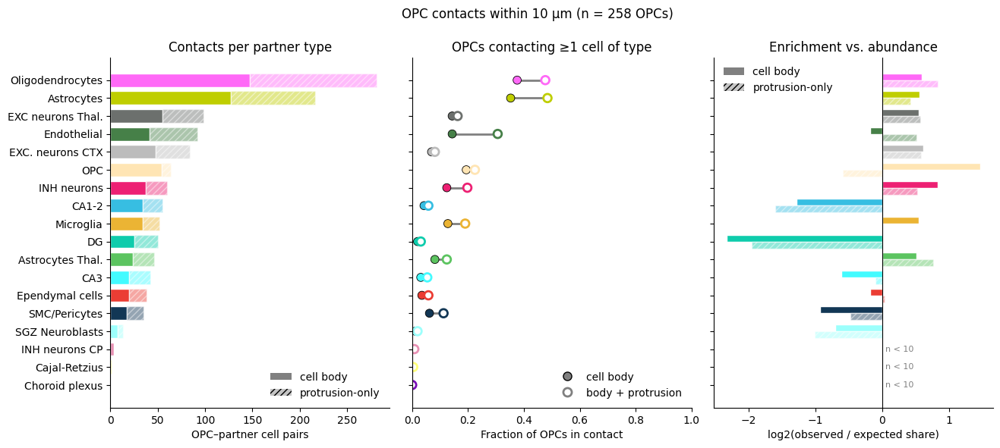

In [6]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

_ct = sdata["table"].obs["cell_type"]
_cats = list(_ct.cat.categories) if isinstance(_ct.dtype, pd.CategoricalDtype) else sorted(_ct.unique())
ct_colors = dict(zip(_cats, sdata["table"].uns["cell_type_colors"]))

order = opc_summary.sort_values("pairs_total", ascending=True).index
cols = [ct_colors[c] for c in order]
y = np.arange(len(order))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True, gridspec_kw={"wspace": 0.08})

# (a) Number of OPC-partner pairs: body (solid) + protrusion-only (hatched)
ax = axes[0]
b = opc_summary.loc[order, "pairs_body"].to_numpy()
p = opc_summary.loc[order, "pairs_protrusion_only"].to_numpy()
ax.barh(y, b, color=cols, edgecolor="white", linewidth=1, height=0.75)
ax.barh(y, p, left=b, color=cols, alpha=0.45, hatch="////", edgecolor="white", linewidth=1, height=0.75)
ax.set_yticks(y, order)
ax.set_xlabel("OPC–partner cell pairs")
ax.set_title("Contacts per partner type")
ax.legend(handles=[Patch(facecolor="grey", label="cell body"),
                   Patch(facecolor="grey", alpha=0.45, hatch="////", label="protrusion-only")],
          frameon=False, loc="lower right")

# (b) Fraction of OPCs touching >=1 cell of each type
ax = axes[1]
fb = opc_summary.loc[order, "frac_focal_body"].to_numpy()
ft = opc_summary.loc[order, "frac_focal_total"].to_numpy()
ax.hlines(y, fb, ft, color="grey", linewidth=2, zorder=1)
ax.scatter(fb, y, s=60, color=cols, edgecolor="black", linewidth=0.6, zorder=2, label="cell body")
ax.scatter(ft, y, s=60, facecolor="white", edgecolor=cols, linewidth=2, zorder=2, label="body + protrusion")
ax.set_xlim(0, 1)
ax.set_xlabel("Fraction of OPCs in contact")
ax.set_title("OPCs contacting ≥1 cell of type")
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markersize=8, color="grey", markeredgecolor="black", label="cell body"),
                   Line2D([], [], marker="o", linestyle="", markersize=8, markerfacecolor="white", markeredgecolor="grey", markeredgewidth=2, label="body + protrusion")],
          frameon=False, loc="lower right")

# (c) Enrichment over cell-type abundance: body vs protrusion-only contacts
ax = axes[2]
# Enrichment is unstable for types with very few contacts - leave those blank
MIN_PAIRS_ENRICH = 10
low_n = (opc_summary.loc[order, "pairs_total"] < MIN_PAIRS_ENRICH).to_numpy()
eb = np.where(low_n, np.nan, opc_summary.loc[order, "log2_enrich_body"].clip(-4, 4))
ep = np.where(low_n, np.nan, opc_summary.loc[order, "log2_enrich_protrusion_only"].clip(-4, 4))
h = 0.38
ax.barh(y + h / 2, eb, height=h, color=cols, edgecolor="white", linewidth=1, label="cell body")
ax.barh(y - h / 2, ep, height=h, color=cols, alpha=0.45, hatch="////", edgecolor="white", linewidth=1, label="protrusion-only")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("log2(observed / expected share)")
for yi in y[low_n]:
    ax.text(0.05, yi, f"n < {MIN_PAIRS_ENRICH}", va="center", fontsize=8, color="grey")
ax.set_title("Enrichment vs. abundance")
ax.legend(handles=[Patch(facecolor="grey", label="cell body"),
                   Patch(facecolor="grey", alpha=0.45, hatch="////", label="protrusion-only")],
          frameon=False, loc="upper left")

for ax in axes:
    ax.grid(False)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
fig.suptitle(f"OPC contacts within {OPC_CONTACT_DIST:g} µm (n = {len(opc_prot_tx)} OPCs)", y=0.99)
fig.savefig(os.path.join(saving_path, "opc_contacts_body_vs_protrusion_10um.pdf"), bbox_inches="tight")
plt.show()

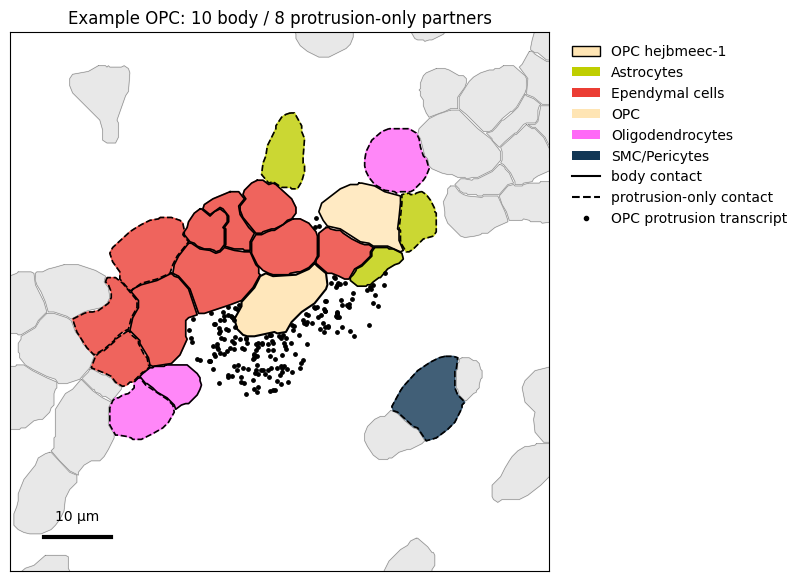

In [7]:
# Example OPC: the one with the most protrusion-only partners
from shapely.geometry import box as _box
from matplotlib.lines import Line2D

_po = opc_pairs[opc_pairs["mode"] == "protrusion_only"].groupby("focal_id").size()
ex_id = _po.idxmax()
ex_pairs = opc_pairs[opc_pairs["focal_id"] == ex_id]
polys_all = sdata.shapes["cell_boundaries"]
cid2type = dict(zip(sdata["table"].obs["cell_id"].astype(str), sdata["table"].obs["cell_type"].astype(str)))

ex_poly = polys_all.loc[ex_id].geometry
ex_pts = opc_prot_points[opc_prot_points["parent"] == ex_id]
cx, cy = ex_poly.centroid.x, ex_poly.centroid.y
half = max(40.0, np.abs(ex_pts[["x", "y"]].to_numpy() - [cx, cy]).max() + 15) if len(ex_pts) else 40.0
win = _box(cx - half, cy - half, cx + half, cy + half)
in_win = polys_all[polys_all.intersects(win)]

mode_of = dict(zip(ex_pairs["partner_id"], ex_pairs["mode"]))
fig, ax = plt.subplots(figsize=(7, 7))
for cid, g in in_win.geometry.items():
    t = cid2type.get(cid)
    m = mode_of.get(cid)
    xs, ys = g.exterior.xy if g.geom_type == "Polygon" else max(g.geoms, key=lambda q: q.area).exterior.xy
    if cid == ex_id:
        ax.fill(xs, ys, color=ct_colors["OPC"], alpha=0.9, zorder=3)
        ax.plot(xs, ys, color="black", linewidth=1.5, zorder=4)
    elif m is not None:
        ax.fill(xs, ys, color=ct_colors.get(t, "grey"), alpha=0.8, zorder=2)
        ax.plot(xs, ys, color="black", linewidth=1.2, linestyle="-" if m != "protrusion_only" else "--", zorder=4)
    else:
        ax.fill(xs, ys, color="lightgrey", alpha=0.5, zorder=1)
        ax.plot(xs, ys, color="grey", linewidth=0.4, zorder=1)
ax.scatter(ex_pts["x"], ex_pts["y"], s=6, color="black", zorder=5)
ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
ax.plot([cx - half + 5, cx - half + 15], [cy + half - 5] * 2, color="black", linewidth=3)
ax.text(cx - half + 10, cy + half - 7, "10 µm", ha="center", va="bottom")

partner_types = sorted({cid2type[c] for c in ex_pairs["partner_id"]})
handles = [Patch(facecolor=ct_colors["OPC"], edgecolor="black", label=f"OPC {ex_id}")]
handles += [Patch(facecolor=ct_colors[t], label=t) for t in partner_types]
handles += [Line2D([], [], color="black", linestyle="-", label="body contact"),
            Line2D([], [], color="black", linestyle="--", label="protrusion-only contact"),
            Line2D([], [], marker="o", color="black", linestyle="", markersize=3, label="OPC protrusion transcript")]
ax.legend(handles=handles, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title(f"Example OPC: {int((ex_pairs['mode'] != 'protrusion_only').sum())} body / "
             f"{int((ex_pairs['mode'] == 'protrusion_only').sum())} protrusion-only partners")
fig.savefig(os.path.join(saving_path, "opc_contacts_example_10um.pdf"), bbox_inches="tight")
plt.show()

### Is the protrusion gain specific to OPCs?

Every cell with an extracellular uRNA halo reaches further than its body alone, so the protrusion-only contacts of OPCs need a baseline. Here the same 10 µm analysis is run with every cell type as the focal type, comparing the number of protrusion-only partners per cell and the relative gain over body contacts.

In [8]:
all_focal = []
for ct in tqdm(sorted(sdata["table"].obs["cell_type"].astype(str).unique()), desc="focal cell types"):
    pr_ct, ptx_ct, _ = focal_celltype_contacts(
        sdata, focal_type=ct, cell_type_key="cell_type", contact_dist=OPC_CONTACT_DIST,
        min_score=0.1, min_protrusion_tx=1, extra_tx=extra_tx, verbose=False,
    )
    per_cell = pr_ct.groupby("focal_id").agg(
        body=("body", "sum"), protrusion_only=("mode", lambda m: (m == "protrusion_only").sum()),
    ).reindex(ptx_ct.index, fill_value=0)
    per_cell["n_protrusion_tx"] = ptx_ct
    per_cell["focal_type"] = ct
    all_focal.append(per_cell)
all_focal = pd.concat(all_focal)
all_focal.to_csv(os.path.join(saving_path, "allcelltypes_contacts_per_cell_10um.csv"))

focal_summary = all_focal.groupby("focal_type").agg(
    n_cells=("body", "size"),
    body_partners_mean=("body", "mean"),
    protrusion_only_partners_mean=("protrusion_only", "mean"),
    protrusion_tx_median=("n_protrusion_tx", "median"),
)
focal_summary["protrusion_gain"] = (
    all_focal.groupby("focal_type")["protrusion_only"].sum() / all_focal.groupby("focal_type")["body"].sum()
)
focal_summary = focal_summary.sort_values("protrusion_gain", ascending=False)
focal_summary.to_csv(os.path.join(saving_path, "allcelltypes_protrusion_gain_10um.csv"))

opc_rank = focal_summary.index.get_loc("OPC") + 1
print(f"OPC protrusion gain: {focal_summary.loc['OPC', 'protrusion_gain']:.1%} "
      f"(rank {opc_rank}/{len(focal_summary)}; median across types "
      f"{focal_summary['protrusion_gain'].median():.1%})")
focal_summary.round(3)

focal cell types:   0%|          | 0/18 [00:00<?, ?it/s]

focal cell types:   6%|▌         | 1/18 [00:03<01:06,  3.89s/it]

focal cell types:  11%|█         | 2/18 [00:05<00:43,  2.69s/it]

focal cell types:  17%|█▋        | 3/18 [00:09<00:50,  3.35s/it]

focal cell types:  22%|██▏       | 4/18 [00:13<00:47,  3.40s/it]

...

focal cell types:  94%|█████████▍| 17/18 [00:40<00:02,  2.01s/it]

focal cell types: 100%|██████████| 18/18 [00:41<00:00,  1.89s/it]

focal cell types: 100%|██████████| 18/18 [00:41<00:00,  2.32s/it]

OPC protrusion gain: 77.1% (rank 3/18; median across types 51.1%)


,n_cells,body_partners_mean,protrusion_only_partners_mean,protrusion_tx_median,protrusion_gain
focal_type,,,,,
EXC neurons Thal.,497,3.284,2.789,864.0,0.849
Oligodendrocytes,1290,3.172,2.457,249.5,0.774
OPC,258,2.694,2.078,376.5,0.771
EXC. neurons CTX,413,4.206,3.232,814.0,0.769
Astrocytes Thal.,222,3.577,2.577,475.5,0.720
Astrocytes,1139,2.861,2.057,380.0,0.719
Cajal-Retzius,40,2.700,1.900,294.5,0.704
Endothelial,614,3.068,1.943,213.5,0.633
Microglia,307,3.453,1.814,268.0,0.525


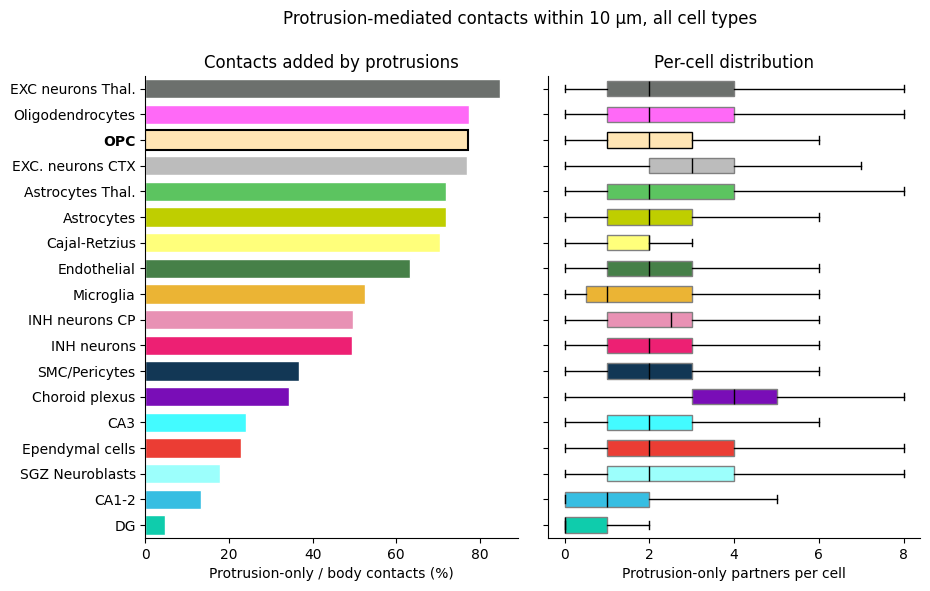

In [9]:
order_f = focal_summary.sort_values("protrusion_gain").index
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True, gridspec_kw={"wspace": 0.08})
yf = np.arange(len(order_f))
edge = ["black" if c == "OPC" else "white" for c in order_f]
lw = [1.5 if c == "OPC" else 1 for c in order_f]

ax = axes[0]
ax.barh(yf, focal_summary.loc[order_f, "protrusion_gain"] * 100,
        color=[ct_colors[c] for c in order_f], edgecolor=edge, linewidth=lw, height=0.75)
ax.set_xlabel("Protrusion-only / body contacts (%)")
ax.set_title("Contacts added by protrusions")

# Per-cell distribution of protrusion-only partners
ax = axes[1]
data = [all_focal.loc[all_focal["focal_type"] == c, "protrusion_only"].to_numpy() for c in order_f]
bp = ax.boxplot(data, positions=yf, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                medianprops={"color": "black"})
for patch, c in zip(bp["boxes"], order_f):
    patch.set_facecolor(ct_colors[c])
    patch.set_edgecolor("black" if c == "OPC" else "grey")
ax.set_xlabel("Protrusion-only partners per cell")
ax.set_title("Per-cell distribution")

for ax in axes:
    ax.grid(False)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
axes[0].set_yticks(yf, order_f)  # after boxplot, which resets the shared y ticks
axes[0].get_yticklabels()[list(order_f).index("OPC")].set_fontweight("bold")
fig.suptitle(f"Protrusion-mediated contacts within {OPC_CONTACT_DIST:g} µm, all cell types", y=0.99)
fig.savefig(os.path.join(saving_path, "allcelltypes_protrusion_gain_10um.pdf"), bbox_inches="tight")
plt.show()

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box


def plot_cell_contacts(
    sdata,
    # ── Cell selection ────────────────────────────────────────────────────────
    cell_id: int | str | list | None = None,       # select by specific cell_id(s)
    cell_type: str | list[str] | None = None,      # select by cell type label
    cell_type_key: str = "leiden",                 # column in obs for cell type
    contact_key: str = "contact_cell_ids",         # obs column from store_in_sdata
    # ── Visual ────────────────────────────────────────────────────────────────
    color_by: str = "leiden",                      # color focal + contact cells by this obs column
    palette: str = "tab20",
    focal_size: float = 30.0,                      # scatter size for focal cells
    contact_size: float = 20.0,                    # scatter size for contact cells
    bg_size: float = 3.0,                          # scatter size for background cells
    bg_color: str = "#AAAAAA",
    bg_alpha: float = 0.3,
    edge_color: str = "white",
    edge_alpha: float = 0.5,
    edge_linewidth: float = 0.5,
    fig_bg_color: str = "black",
    show_boundaries: bool = True,
    shapes_key: str = "cell_boundaries",
    boundary_linewidth: float = 0.3,
    boundary_alpha: float = 0.3,
    # ── ROI ──────────────────────────────────────────────────────────────────
    use_roi: bool = False,
    roi: tuple | None = None,                      # (xmin, xmax, ymin, ymax)
    padding: float = 0.0,
    figsize: tuple = (18, 18),
) -> tuple:
    """
    Plot focal cells (selected by cell_id or cell_type) and their transcript-based
    contact neighbours as spatially embedded points connected by edges.
    All other cells rendered as grey background dots.
    """

    # ── 1. Cell obs setup ─────────────────────────────────────────────────────
    cells    = sdata["table"]
    cell_obs = cells.obs.copy()
    cell_obs["cell_id"] = cell_obs["cell_id"].astype(str).str.strip()
    centroids = pd.DataFrame(
        cells.obsm["spatial"],
        index=cell_obs.index,
        columns=["x", "y"]
    )
    cell_obs = cell_obs.join(centroids)

    # ── 2. Resolve focal cell set ─────────────────────────────────────────────
    if cell_id is not None:
        ids = [str(cell_id)] if not isinstance(cell_id, list) else [str(c) for c in cell_id]
        focal_mask = cell_obs["cell_id"].isin(ids)
    elif cell_type is not None:
        types = [cell_type] if isinstance(cell_type, str) else cell_type
        focal_mask = cell_obs[cell_type_key].astype(str).isin(types)
    else:
        raise ValueError("Provide either cell_id or cell_type to select focal cells.")

    focal_obs = cell_obs[focal_mask]
    if focal_obs.empty:
        print("No cells matched the selection criteria.")
        return None, None

    print(f"Focal cells: {len(focal_obs):,}")

    # ── 3. Resolve contact cells ──────────────────────────────────────────────
    if contact_key not in cell_obs.columns:
        raise KeyError(
            f"'{contact_key}' not found in sdata['table'].obs. "
            "Run celltype_contact_matrix(..., store_in_sdata=True) first."
        )

    focal_cell_ids = set(focal_obs["cell_id"].values)

    # Gather all neighbour cell_ids mentioned by any focal cell
    contact_cell_ids = set()
    for cid in focal_obs["cell_id"]:
        raw = cell_obs.loc[cell_obs["cell_id"] == cid, contact_key].values[0]
        if raw and isinstance(raw, str):
            contact_cell_ids.update(raw.split(";"))

    # Remove focal cells from contact set (they're already highlighted)
    contact_cell_ids -= focal_cell_ids
    contact_obs = cell_obs[cell_obs["cell_id"].isin(contact_cell_ids)]

    print(f"Contact cells: {len(contact_obs):,}")

    # ── 4. Background cells ───────────────────────────────────────────────────
    highlighted_ids = focal_cell_ids | contact_cell_ids
    bg_obs = cell_obs[~cell_obs["cell_id"].isin(highlighted_ids)]

    # ── 5. Color map from obs column ──────────────────────────────────────────
    text_color = "white" if fig_bg_color in ["black", "#000000", "#252525"] else "black"

    all_highlighted = pd.concat([focal_obs, contact_obs])
    unique_labels   = sorted(all_highlighted[color_by].astype(str).unique())

    # Try uns colors first (mirrors reference)
    colors = None
    try:
        uns_colors = cells.uns[color_by + "_colors"]
        cat_order  = list(cells.obs[color_by].astype("category").cat.categories)
        color_map  = dict(zip(cat_order, uns_colors))
        colors     = {lbl: color_map[lbl] for lbl in unique_labels if lbl in color_map}
    except (KeyError, AttributeError):
        colors = None

    if not colors or len(colors) < len(unique_labels):
        cmap_fb = plt.get_cmap(palette)
        colors  = {l: cmap_fb(i / max(1, len(unique_labels) - 1))
                   for i, l in enumerate(unique_labels)}

    # ── 6. ROI / axis limits ──────────────────────────────────────────────────
    if use_roi and roi is not None:
        x_min, x_max, y_min, y_max = roi
    elif padding > 0:
        x_min = cell_obs["x"].min() - padding
        x_max = cell_obs["x"].max() + padding
        y_min = cell_obs["y"].min() - padding
        y_max = cell_obs["y"].max() + padding
    else:
        x_min, x_max = cell_obs["x"].min(), cell_obs["x"].max()
        y_min, y_max = cell_obs["y"].min(), cell_obs["y"].max()

    # ── 7. Cell boundaries ────────────────────────────────────────────────────
    gdf = None
    if show_boundaries and shapes_key in sdata:
        cb        = sdata[shapes_key]
        df_shapes = cb.copy()
        try:
            from spatialdata import get_transformation
            trans = get_transformation(cb)
            if hasattr(trans, "matrix") and trans.matrix is not None:
                m      = trans.matrix
                params = [m[0,0], m[0,1], m[1,0], m[1,1], m[0,2], m[1,2]]
                df_shapes["geometry"] = df_shapes["geometry"].apply(
                    lambda g: affine_transform(g, params)
                )
        except:
            pass
        gdf = gpd.GeoDataFrame(df_shapes, geometry="geometry")
        if use_roi and roi is not None:
            gdf = gdf[gdf.geometry.intersects(box(x_min, y_min, x_max, y_max))]

    # ── 8. Build edges: focal centroid → contact centroid ────────────────────
    # Index contact_obs by cell_id for fast lookup
    contact_xy = contact_obs.set_index("cell_id")[["x", "y"]]
    focal_xy   = focal_obs.set_index("cell_id")[["x", "y"]]

    edges = []
    for cid in focal_obs["cell_id"]:
        raw = cell_obs.loc[cell_obs["cell_id"] == cid, contact_key].values[0]
        if not raw or not isinstance(raw, str):
            continue
        neighbours = raw.split(";")
        fx, fy     = focal_xy.loc[cid, ["x", "y"]]
        for nb in neighbours:
            if nb in contact_xy.index:
                nx, ny = contact_xy.loc[nb, ["x", "y"]]
                edges.append([(fx, fy), (nx, ny)])

    # ── 9. Figure ─────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, facecolor=fig_bg_color)
    ax.set_facecolor(fig_bg_color)

    # Background cells
    ax.scatter(
        bg_obs["x"], bg_obs["y"],
        c=bg_color, s=bg_size, alpha=bg_alpha,
        edgecolors="none", zorder=1, rasterized=True
    )

    # Edges
    if edges:
        lc = LineCollection(
            edges, colors=edge_color, linewidths=edge_linewidth,
            alpha=edge_alpha, zorder=2
        )
        ax.add_collection(lc)

    # Contact cells
    for lbl in unique_labels:
        subset = contact_obs[contact_obs[color_by].astype(str) == lbl]
        if subset.empty:
            continue
        ax.scatter(
            subset["x"], subset["y"],
            color=colors[lbl], s=contact_size,
            edgecolors="none", zorder=3,
            label=f"{lbl}" if lbl not in [l for l in focal_obs[color_by].astype(str).unique()] else None
        )

    # Focal cells (on top, with ring)
    for lbl in unique_labels:
        subset = focal_obs[focal_obs[color_by].astype(str) == lbl]
        if subset.empty:
            continue
        ax.scatter(
            subset["x"], subset["y"],
            color=colors[lbl], s=focal_size,
            edgecolors=text_color, linewidths=0.8,
            zorder=4, label=f"{lbl} (focal)"
        )

    # Cell boundaries
    if gdf is not None:
        border_color = "white" if fig_bg_color == "black" else "black"
        gdf.plot(
            ax=ax, facecolor="none", edgecolor=border_color,
            linewidth=boundary_linewidth, alpha=boundary_alpha, zorder=5
        )

    # ── 10. Axes & legend ─────────────────────────────────────────────────────
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    plt.axis("off")

    selection_label = (
        f"cell_id={cell_id}" if cell_id is not None
        else f"{cell_type_key}={cell_type}"
    )
    plt.title(
        f"Cell contacts | {selection_label}  ·  n_focal={len(focal_obs)}  ·  n_contacts={len(contact_obs)}",
        color=text_color, fontsize=13, pad=12
    )

    box_pos = ax.get_position()
    ax.set_position([box_pos.x0, box_pos.y0, box_pos.width * 0.82, box_pos.height])
    ax.legend(
        loc="center left", bbox_to_anchor=(1, 0.5),
        facecolor=fig_bg_color, edgecolor=text_color,
        labelcolor=text_color, markerscale=4, fontsize=9,
        framealpha=0.6
    )

    return fig, ax

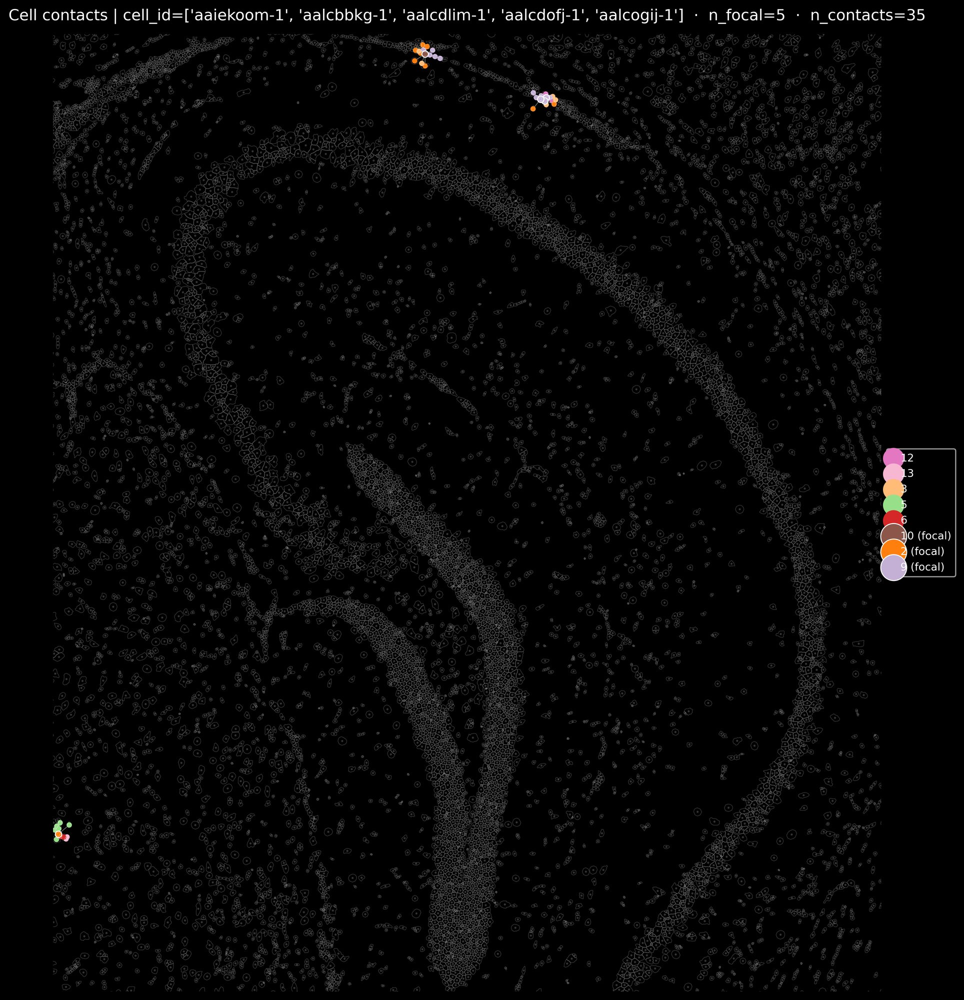

In [35]:
# By a single cell_id
fig, ax = plot_cell_contacts(sdata, cell_id=list(sdata['table'].obs['cell_id'][0:5]))


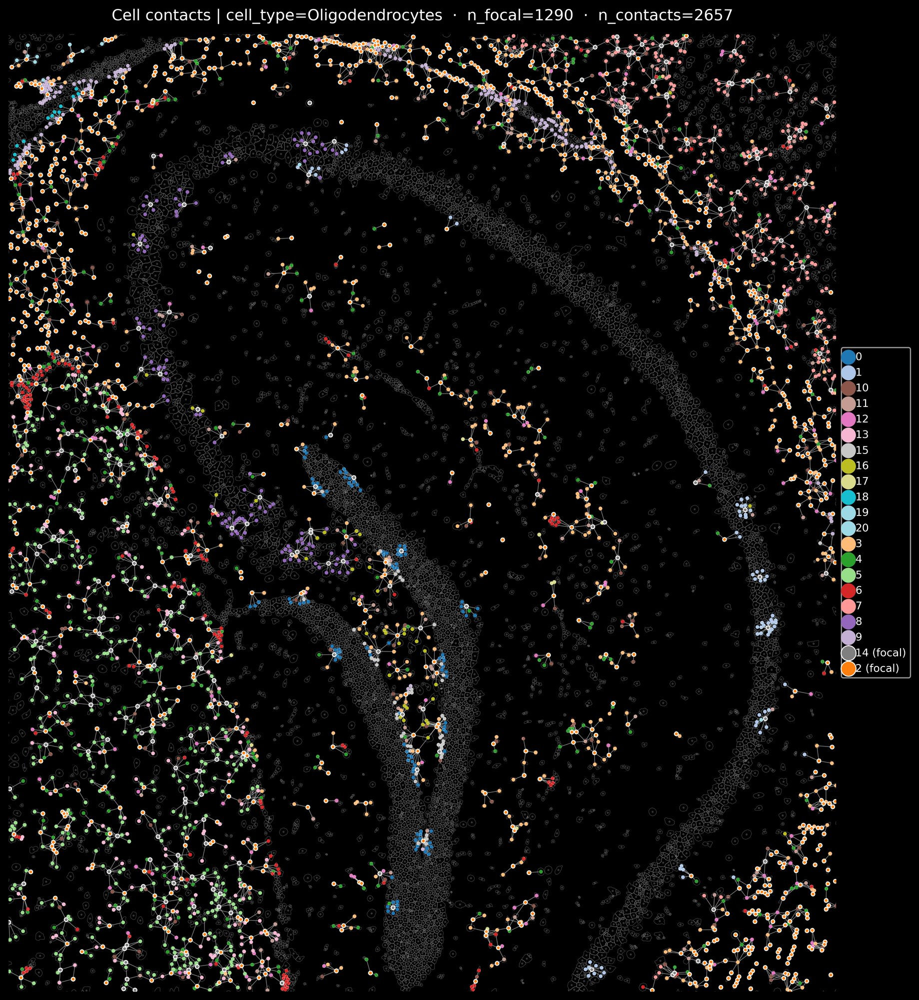

In [32]:
fig, ax = plot_cell_contacts(sdata, cell_type="Oligodendrocytes", cell_type_key="cell_type",focal_size= 10.0,                      # scatter size for focal cells
    contact_size= 10.0,                    # scatter size for contact cells
    bg_size = 3.0 )


In [33]:
hi


<Figure size 1000x1000 with 0 Axes>

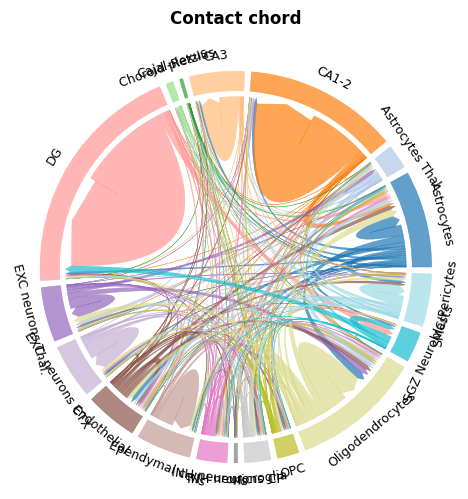

In [6]:
# Chord diagram, no sdata needed if you pass your own colors via kwargs
# NOTE: pl.celltype_contact_matrix(kind="chord") creates its own throwaway
# plt.figure() and draws onto a SECOND figure that mpl_chord_diagram creates
# internally, so the fig it returns is always empty; plt.gcf() after the call
# is the one that actually has the chord diagram on it.
pl.celltype_contact_matrix(mat, kind="chord", title="Contact chord")
fig = plt.gcf()
fig.savefig(os.path.join(saving_path,"chord_cell_type_contacts_r5.pdf"))

In [9]:
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from tqdm import tqdm


def compute_target_score_bounded(
    sdata,
    layer="transcripts",
    gene_key="gene",
    coords_key=None,
    lambda_decay=0.5,
    celltype_key="cell_type",
    k_neighbors=200,
    batch_size=200_000,
    copy=False,
):
    """Memory-bounded drop-in for troutpy.tl.compute_target_score.

    The upstream function queries k=n_cells neighbors for every
    extracellular transcript, producing an (n_transcripts x n_cells)
    distance matrix. On this dataset (9,185 cells x 5.75M extracellular
    transcripts) that is ~845GB and OOM-kills the kernel in under a
    minute. With lambda_decay=0.5, a cell's contribution decays as
    exp(-0.5*d): the median nearest-neighbor distance here is ~8.5 units
    (contribution ~0.014) and the 100th-nearest is ~94 units
    (contribution ~1e-20). Restricting to the k_neighbors nearest cells
    per transcript reproduces the same result well beyond float
    precision while keeping memory bounded, and batching the KDTree
    query keeps peak memory constant regardless of dataset size.
    """
    if coords_key is None:
        coords_key = ["x", "y"]
    xcoord, ycoord = coords_key

    transcripts = sdata.points[layer].compute()
    coord_cells = sdata["table"].obsm["spatial"]
    cell_types = sdata["table"].obs[celltype_key]
    all_cell_types = cell_types.unique()
    type_to_code = {ct: i for i, ct in enumerate(all_cell_types)}
    cell_type_codes = cell_types.map(type_to_code).to_numpy()

    extracellular_transcripts = transcripts[transcripts["extracellular"]]
    n_transcripts = len(extracellular_transcripts)
    n_types = len(all_cell_types)
    k = min(k_neighbors, len(coord_cells))

    kdtree = cKDTree(coord_cells)
    transcript_coords = extracellular_transcripts[[xcoord, ycoord]].to_numpy()

    target_scores = np.zeros((n_transcripts, n_types), dtype=np.float32)

    for start in tqdm(range(0, n_transcripts, batch_size)):
        end = min(start + batch_size, n_transcripts)
        batch_coords = transcript_coords[start:end]
        distances, indices = kdtree.query(batch_coords, k=k)
        exp_decay = np.exp(-lambda_decay * distances).astype(np.float32)
        types = cell_type_codes[indices]

        b = end - start
        rows = np.repeat(np.arange(b, dtype=np.int32), k)
        cols = types.ravel().astype(np.int32)
        data = exp_decay.ravel()
        batch_scores = coo_matrix((data, (rows, cols)), shape=(b, n_types)).toarray()
        target_scores[start:end] = batch_scores

    target_scores_table = pd.DataFrame(target_scores, index=extracellular_transcripts.index, columns=all_cell_types)

    prob_table = sc.AnnData(target_scores_table)
    prob_table.obs[gene_key] = list(extracellular_transcripts[gene_key].astype(str))
    prob_table.obsm["spatial"] = extracellular_transcripts[[xcoord, ycoord]].to_numpy()
    prob_table.obs_names = prob_table.obs_names.astype(str)
    sdata.tables["target_score"] = prob_table

    return sdata.copy() if copy else None

In [10]:
compute_target_score_bounded(sdata,layer="transcripts",lambda_decay=0.5,celltype_key="cell_type",gene_key='gene')

  0%|          | 0/29 [00:00<?, ?it/s]

  3%|▎         | 1/29 [00:04<02:00,  4.32s/it]

  7%|▋         | 2/29 [00:08<01:51,  4.12s/it]

 10%|█         | 3/29 [00:12<01:44,  4.02s/it]

 14%|█▍        | 4/29 [00:16<01:39,  3.99s/it]

...

 90%|████████▉ | 26/29 [01:44<00:12,  4.01s/it]

 93%|█████████▎| 27/29 [01:48<00:08,  4.04s/it]

 97%|█████████▋| 28/29 [01:52<00:04,  4.07s/it]

100%|██████████| 29/29 [01:55<00:00,  3.80s/it]

100%|██████████| 29/29 [01:55<00:00,  3.99s/it]

In [11]:
import numpy as np
from scipy.sparse import issparse


def compute_communication_strength_bounded(sdata, source_layer="source_score", target_layer="target_score"):
    """Vectorized, dtype-safe drop-in for troutpy.tl.compute_communication_strength.

    The upstream function loops row-by-row using `source_table[id]` /
    `target_table[id]` AnnData indexing. That's (a) very slow across
    millions of transcripts and (b) breaks outright here: anndata now
    refuses ambiguous integer-valued single-label indexing, and
    target_score's row index is int64. It also assumes every id in
    source_score has a matching row in target_score; that's not true on
    this data since target_score is restricted to `extracellular`==True
    transcripts (5.75M), a subset of source_score's broader transcript
    set (8.39M) - the extra ids simply can't form a source x target
    contribution (no target vector to pair with), so they're dropped
    here explicitly instead of raising a KeyError partway through a
    multi-hour loop.
    """
    source_table = sdata.tables[source_layer]
    target_table = sdata.tables[target_layer]

    source_table.obs_names = source_table.obs_names.astype(str)
    target_table.obs_names = target_table.obs_names.astype(str)

    common_ids = source_table.obs_names[source_table.obs_names.isin(target_table.obs_names)]
    print(f"{len(common_ids)}/{source_table.n_obs} source-score transcripts have a matching target-score entry")

    def _dense(X):
        return X.toarray() if issparse(X) else np.asarray(X)

    X_source = _dense(source_table[common_ids].X).astype(np.float32)
    X_target = _dense(target_table[common_ids].X).astype(np.float32)

    interaction_strength = X_source[:, :, None] * X_target[:, None, :]
    sdata["source_score"].uns["interaction_strength"] = interaction_strength

In [12]:
compute_communication_strength_bounded(sdata)

5753417/8388470 source-score transcripts have a matching target-score entry


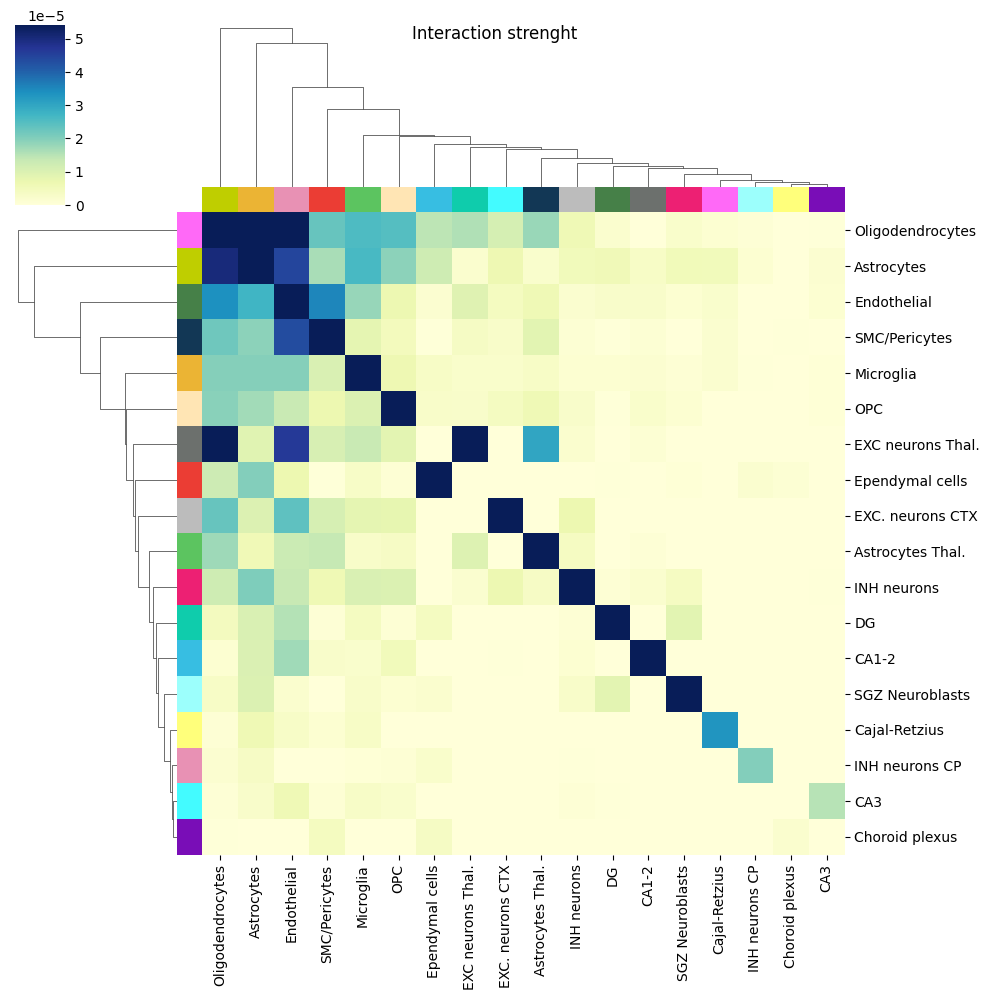

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

interaction_strength = sdata["source_score"].uns["interaction_strength"]
source_table = sdata["source_score"]
target_table = sdata["target_score"]

celltype_ints = np.mean(interaction_strength, axis=0)
celltype_ints_table = pd.DataFrame(celltype_ints, index=source_table.var.index, columns=target_table.var.index)

try:
    colors = sdata["table"].uns["cell_type_colors"]
except KeyError:
    colpalette = plt.get_cmap("tab20")
    colors = [colpalette(i) for i in range(len(np.unique(source_table.var.index)))]

g = sns.clustermap(celltype_ints_table, cmap="YlGnBu", row_colors=colors, col_colors=colors, dendrogram_ratio=0.2, figsize=(10, 10), vmax=np.percentile(celltype_ints_table.values, 95))
g.fig.suptitle("Interaction strenght")
g.fig.savefig(os.path.join(saving_path, "heatmap_n_interaction_strenght.pdf"))
plt.show()

In [14]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

def count_neighbors_by_cell_type(adata, spatial_key="spatial", cell_type_key="cell_type", distance=50):
    """
    Count the number of neighboring cells for each pair of cell types within a given distance.

    Parameters:
    - adata: AnnData object with cell_type annotation and spatial coordinates
    - spatial_key: key in adata.obs or adata.obsm containing spatial coordinates
    - cell_type_key: key in adata.obs containing cell type annotations
    - distance: radius within which to count neighbors

    Returns:
    - DataFrame (cell_type x cell_type) with counts of neighboring cell-type pairs
    """
    # Get spatial coordinates
    if spatial_key in adata.obsm:
        coords = adata.obsm[spatial_key]
    else:
        coords = adata.obs[spatial_key].tolist()  # if it's a column with arrays

    coords = np.asarray(coords)
    cell_types = adata.obs[cell_type_key].values
    unique_cell_types = np.unique(cell_types)

    # Create a BallTree for fast spatial queries
    tree = BallTree(coords)

    # Query neighbors within distance (excluding self)
    neighbors = tree.query_radius(coords, r=distance)

    # Initialize count matrix
    count_matrix = pd.DataFrame(
        0, index=unique_cell_types, columns=unique_cell_types, dtype=int
    )

    for i, nbr_indices in enumerate(neighbors):
        source_type = cell_types[i]
        for j in nbr_indices:
            if i == j:
                continue  # skip self
            target_type = cell_types[j]
            count_matrix.loc[source_type, target_type] += 1

    return count_matrix


In [15]:
df = count_neighbors_by_cell_type(sdata['table'], spatial_key="spatial", cell_type_key="cell_type", distance=30)

In [16]:
def plot_cell_contact_heatmap(df, sdata, celltype_key="cell type", cmap="Reds", dendrogram_ratio=0.1, vmax=None):
    """
    Plot a heatmap of cell-cell contacts (df), with cell type colors and order matching the interaction plot.

    Parameters
    ----------
    df : pd.DataFrame
        Square DataFrame with cell types on both axes (same as interaction matrix).
    sdata : SpatialData
        SpatialData object containing cell type color and order info.
    celltype_key : str
        Key in `sdata['table'].obs` used for cell type annotation.
    cmap : str
        Color map for the heatmap.
    dendrogram_ratio : float
        Ratio for dendrograms in seaborn clustermap.
    vmax : float, optional
        Max value for colormap scaling (e.g. a percentile of df.values, to avoid a
        single dominant pair washing out the rest of the heatmap).
    """

    # Match order from interaction strength plot
    source_order = sdata["source_score"].var.index
    target_order = sdata["target_score"].var.index

    df_ordered = df.loc[source_order, target_order]

    # Get colors for cell types
    try:
        cols = dict(zip(
            np.unique(sdata["table"].obs[celltype_key]),
            sdata["table"].uns[celltype_key + "_colors"]
        ))
        colors = [cols[c] for c in source_order]
    except KeyError:
        colpalette = plt.get_cmap("tab20")
        colors = [colpalette(i) for i in range(len(source_order))]

    # Plot
    g = sns.clustermap(
        df_ordered,
        row_cluster=False,
        col_cluster=False,
        row_colors=colors,
        col_colors=colors,
        cmap=cmap,
        vmax=vmax,
        dendrogram_ratio=dendrogram_ratio,
        linewidths=0,
        cbar_pos=(0.02, 0.8, 0.02, 0.15),  # left, bottom, width, height
    )

    g.fig.suptitle("Cell-Cell Contacts", y=1.05, fontsize=14)
    plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)
    plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
    g.ax_heatmap.grid(False)


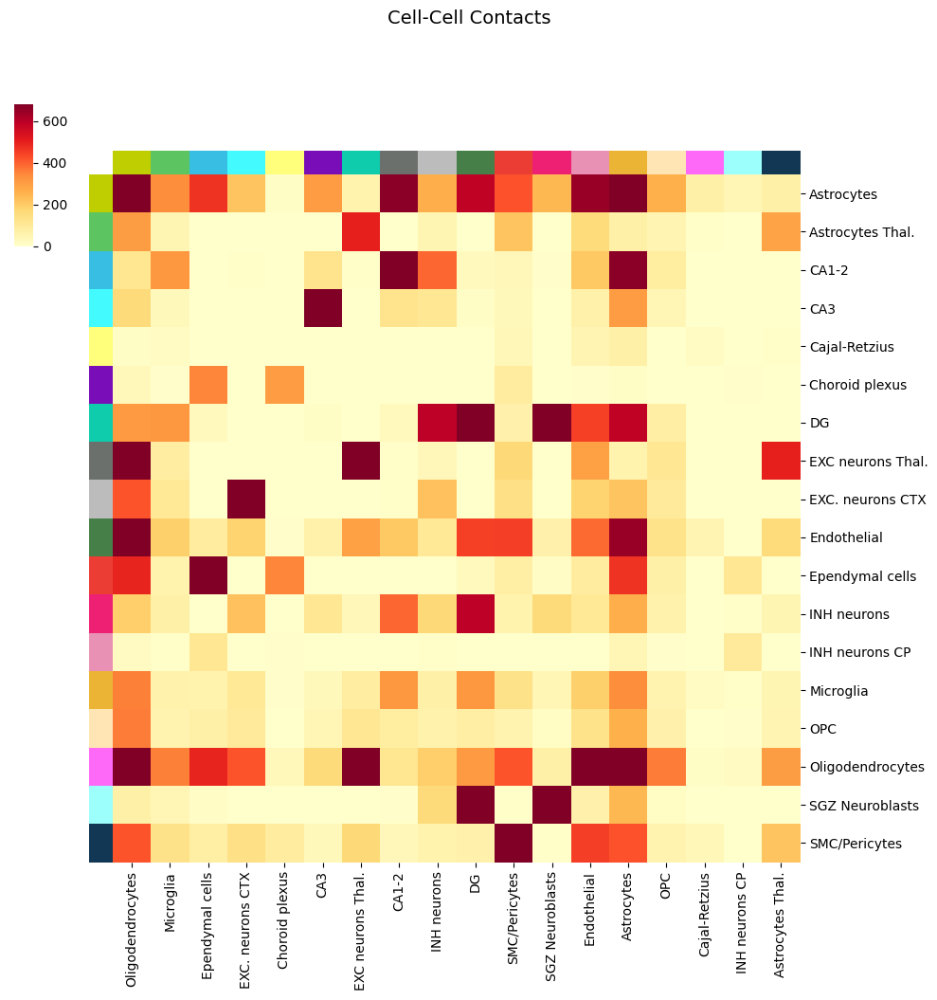

In [17]:
fig=plot_cell_contact_heatmap(df, sdata, celltype_key="cell_type", cmap="YlOrRd", dendrogram_ratio=0.1, vmax=np.percentile(df.values, 95))
plt.savefig(os.path.join(saving_path,'heatmap_cell_cell_contact.pdf'))

In [16]:
intes=sdata['source_score'].uns['interaction_strength']
source_ct=sdata['source_score'].var.index
target_ct=sdata['target_score'].var.index

annodict=dict(zip(sdata['table'].obs['leiden'],sdata['table'].obs['cell_type']))
celltype_ints=np.sum(intes,axis=0)
celltype_int_table=pd.DataFrame(celltype_ints,index=source_ct,columns=target_ct)

In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import normalize
from scipy.spatial.distance import cosine
from scipy.stats import spearmanr, pearsonr

def compare_interaction_matrices(df1, df2, normalize_rows=True, method='pearson'):
    """
    Compare two interaction matrices after aligning and normalizing.

    Parameters:
    - df1, df2: pandas DataFrames with same cell type labels (may be different order)
    - normalize_rows: whether to row-normalize (relative frequencies)
    - method: 'pearson', 'spearman', or 'cosine' for similarity

    Returns:
    - similarity_score: overall similarity score
    - diff_df: DataFrame of difference (df1_norm - df2_norm)
    """
    # Ensure both dataframes have the same order
    common_index = sorted(set(df1.index).intersection(df2.index))
    df1 = df1.loc[common_index, common_index]
    df2 = df2.loc[common_index, common_index]

    # Normalize
    if normalize_rows:
        df1_norm = df1.div(df1.sum(axis=1), axis=0).fillna(0)
        df2_norm = df2.div(df2.sum(axis=1), axis=0).fillna(0)
    else:
        df1_norm = df1 / df1.values.sum()
        df2_norm = df2 / df2.values.sum()

    # Flatten and compare
    v1 = df1_norm.values.flatten()
    v2 = df2_norm.values.flatten()

    if method == 'pearson':
        score, _ = pearsonr(v1, v2)
    elif method == 'spearman':
        score, _ = spearmanr(v1, v2)
    elif method == 'cosine':
        score = 1 - cosine(v1, v2)
    else:
        raise ValueError("Method must be 'pearson', 'spearman', or 'cosine'.")

    # Difference heatmap
    diff_df = df2_norm-df1_norm

    return score, diff_df


In [325]:
celltype_int_table.shape

Similarity score: 0.171


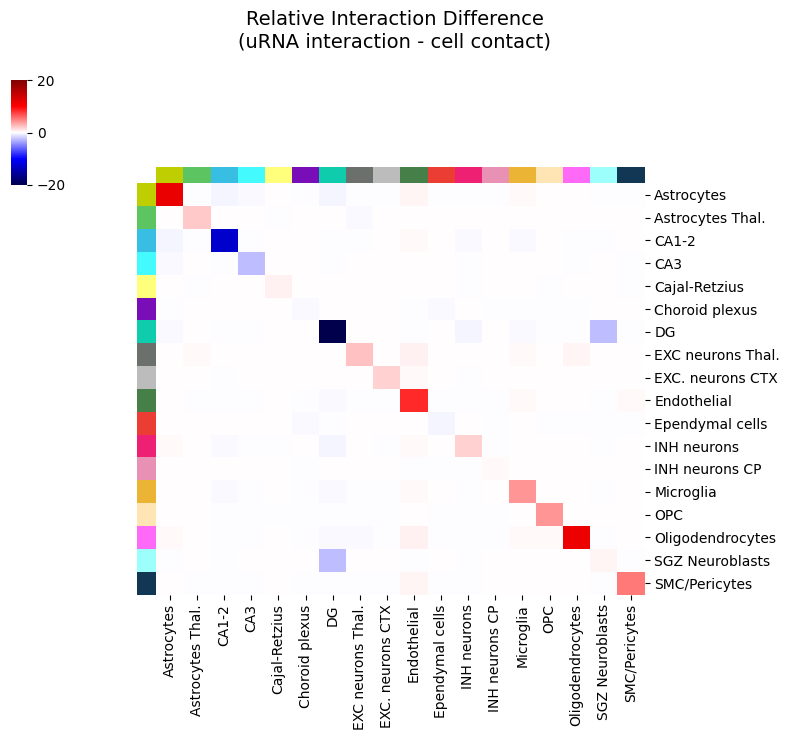

In [18]:
score, diff = compare_interaction_matrices(df, celltype_int_table, normalize_rows=False, method='pearson')
print(f"Similarity score: {score:.3f}")

import seaborn as sns
import matplotlib.pyplot as plt

# Ensure df and celltype_int_table have same order (already assumed done in `compare_interaction_matrices`)
cell_types = diff.index

# Get cell type colors from sdata
cols = dict(zip(
    np.unique(sdata["table"].obs["cell_type"]),
    sdata["table"].uns["cell_type_colors"]
))
row_colors = [cols[ct] for ct in cell_types]
col_colors = [cols[ct] for ct in diff.columns]

# Plot
g = sns.clustermap(
    diff * 100,
    cmap='seismic',
    center=0,
    vmin=-20,
    vmax=20,
    row_colors=row_colors,
    col_colors=col_colors,
    row_cluster=False,
    col_cluster=False,
    figsize=(8, 7),
    cbar_pos=(0.02, 0.8, 0.02, 0.15),  # Adjust if needed
)

g.fig.suptitle("Relative Interaction Difference\n(uRNA interaction - cell contact)", fontsize=14, y=1.05)
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
g.ax_heatmap.grid(False)

plt.savefig(os.path.join(saving_path,'heatmap_interaction_difference_contact_vs_urna_msbrain.pdf'))
plt.show()


In [327]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))
sns.heatmap(diff*100, cmap='seismic', center=0,vmax=20,vmin=-20)
plt.title("Relative Interaction Difference (uRNA conact-cell contact)")
plt.grid(False)
plt.show()
